# Thermal stability of the Trp-cage mini-protein
### All-atom molecular dynamics, free-energy landscapes, NMR validation and an interpretable classifier

**Summary.** Trp-cage (PDB 1L2Y) was simulated for 20 ns in explicit water at 300 K and 360 K with OpenMM (AMBER ff14SB, TIP3P-FB, GPU). At both temperatures the fold stayed native-like. The simulated fluctuations agree with the spread of the experimental NMR ensemble (per-residue RMSF correlation r = 0.79–0.88). Raising the temperature broadened the native basin (higher Cα RMSD, p < 0.001) but did not unfold the protein. The transient losses of native contacts seen at 360 K, including a large one at the end of the run, were traced to the opening of the **Asp9–Arg16 salt bridge**. When contacts involving these two residues are excluded, the native-contact fraction stays above 0.92 in all frames at 300 K and in 99.8% of frames at 360 K. A cross-validated classifier separates the two ensembles only weakly (balanced accuracy 0.62). This confirms that at 360 K the protein samples a broader native ensemble rather than a different state.

**Contents:** 1 Background · 2–4 Setup · 5–7 Simulation · 8–9 Basic descriptors · 10 Ensemble-level analysis · 11 Structural visualization · 12 Discussion · 13 Conclusions · References

## 1. Background and aim

Trp-cage (PDB 1L2Y) is a 20-residue designed mini-protein (sequence NLYIQWLKDGGPSSGRPPPS; Neidigh et al., 2002). It folds cooperatively with an experimental melting temperature of about 315 K and a folding time of a few microseconds (Qiu et al., 2002), which has made it one of the standard benchmarks in computational protein folding (Lindorff-Larsen et al., 2011). The structure has three elements:
- an N-terminal α-helix (residues 2–8);
- a short 3₁₀-helix (residues 11–14);
- a C-terminal polyproline segment (Pro17–Pro19) that packs against the Trp6 indole to form a small hydrophobic core.

These are further stabilized by an Asp9–Arg16 salt bridge.

**Aim.** To compare the conformational ensemble at 300 K with a thermally stressed ensemble at 360 K, and to identify *which* interactions respond first to temperature. The ensembles are characterized with:
- global, contact, secondary-structure and per-residue descriptors;
- free-energy landscapes;
- validation against the experimental NMR ensemble;
- an interpretable machine-learning classifier.

**Relevance.** The same questions arise for protein-based food and biomaterials: which interactions hold a protein's structure together, and which give way first under processing conditions such as heating. The workflow here (simulation, physically motivated descriptors, statistics and interpretable ML) transfers directly to larger systems such as plant proteins and intrinsically disordered regions.

## 2. Environment

- **OpenMM** is the MD engine (GPU-accelerated via CUDA).
- **MDTraj** handles trajectory I/O and structural analysis (RMSD, DSSP, SASA, contacts).
- **scikit-learn** and **SciPy** are used for PCA, the classifier and the statistics.
- **PyMOL** (open source) renders the structures.

In [ ]:
!nvidia-smi -L
!pip install -q "openmm[cuda12]" mdtraj scikit-learn
import openmm.testInstallation
openmm.testInstallation.main()

GPU 0: Tesla T4 (UUID: GPU-419f2639-7d1e-8f42-2a0a-a832300b36b0)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.8/122.8 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.4/14.4 MB 56.1 MB/s eta 0:00:00

OpenMM Version: 8.6.1
Git Revision: b399af4725573963b46d6c1083fdcf7a37615857

There are 4 Platforms available:

1 Reference - Successfully computed forces
2 CPU - Successfully computed forces
3 CUDA - Successfully computed forces
4 OpenCL - Successfully computed forces

Median difference in forces between platforms:

Reference vs. CPU: 6.29029e-06
Reference vs. CUDA: 6.75346e-06
CPU vs. CUDA: 7.63761e-07
Reference vs. OpenCL: 6.74321e-06
CPU vs. OpenCL: 7.85331e-07
CUDA vs. OpenCL: 1.811e-07

All differences are within tolerance.


## 3. Persistent storage

Outputs are written to Google Drive so that completed trajectories survive a Colab disconnection.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
WORK = '/content/drive/MyDrive/trpcage-md'
!mkdir -p $WORK
%cd $WORK

Mounted at /content/drive
/content/drive/MyDrive/trpcage-md


## 4. Input structure

1L2Y is an NMR ensemble of 38 models, and the first model is used as the starting structure.

In [ ]:
!wget -q -O 1L2Y.pdb https://files.rcsb.org/download/1L2Y.pdb
!grep -c '^MODEL' 1L2Y.pdb

38


## 5. Simulation protocol

| Stage | Settings |
|---|---|
| Force field | AMBER ff14SB (`amber14-all.xml`) with TIP3P-FB water |
| Solvation | Cubic box with 1.0 nm padding, neutralized, 0.15 M NaCl |
| Non-bonded | PME electrostatics, 1.0 nm real-space cutoff |
| Constraints | Bonds to hydrogen constrained; hydrogen mass repartitioned to 1.5 amu, allowing a 4 fs time step |
| Integrator | Langevin middle integrator, friction 1 ps⁻¹ |
| Pressure | Monte Carlo barostat, 1 bar (NPT) |
| Minimization | Up to 5000 iterations of L-BFGS |
| Equilibration | 200 ps with harmonic restraints (1000 kJ mol⁻¹ nm⁻²) on protein heavy atoms, to relax the solvent and box density around the native structure |
| Production | Unrestrained NPT; protein-only coordinates saved every 10 ps to XTC; thermodynamic log saved to CSV; periodic checkpoints |


In [ ]:
%%writefile simulate.py

import argparse
import os
import sys
import time
import mdtraj
from mdtraj.reporters import XTCReporter
import openmm as mm
import openmm.app as app
import openmm.unit as u


def pick_platform(name):
    if name != "auto":
        return mm.Platform.getPlatformByName(name)
    available = [mm.Platform.getPlatform(i).getName()
                 for i in range(mm.Platform.getNumPlatforms())]
    for p in ("CUDA", "OpenCL", "CPU"):
        if p in available:
            return mm.Platform.getPlatformByName(p)
    return mm.Platform.getPlatformByName("Reference")

def main():
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--pdb", required=True, help="input structure (e.g. 1L2Y.pdb)")
    ap.add_argument("--temp", type=float, default=300.0, help="temperature, K")
    ap.add_argument("--ns", type=float, default=20.0, help="production length, ns")
    ap.add_argument("--equil_ps", type=float, default=200.0, help="restrained equilibration, ps")
    ap.add_argument("--save_ps", type=float, default=10.0, help="trajectory save interval, ps")
    ap.add_argument("--out", required=True, help="output directory")
    ap.add_argument("--platform", default="auto", help="auto | CUDA | OpenCL | CPU")
    ap.add_argument("--seed", type=int, default=0, help="velocity seed (0 = random)")
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)

    T = args.temp * u.kelvin
    dt = 4.0 * u.femtoseconds
    steps_per_ps = int(round(1.0 * u.picosecond / dt))

    pdb = app.PDBFile(args.pdb)
    ff = app.ForceField("amber14-all.xml", "amber14/tip3pfb.xml")

    modeller = app.Modeller(pdb.topology, pdb.positions)
    modeller.deleteWater()
    modeller.delete([a for a in modeller.topology.atoms() if a.element is not None
                     and a.element.symbol == "H"])
    modeller.addHydrogens(ff, pH=7.0)
    n_protein_atoms = modeller.topology.getNumAtoms()
    modeller.addSolvent(ff, model="tip3p", padding=1.0 * u.nanometer,
                        ionicStrength=0.15 * u.molar, neutralize=True)
    n_atoms = modeller.topology.getNumAtoms()
    print(f"System: {n_protein_atoms} protein atoms, {n_atoms} atoms total")

    system = ff.createSystem(modeller.topology,
                             nonbondedMethod=app.PME,
                             nonbondedCutoff=1.0 * u.nanometer,
                             constraints=app.HBonds,
                             hydrogenMass=1.5 * u.amu)
    system.addForce(mm.MonteCarloBarostat(1.0 * u.bar, T))

    restraint = mm.CustomExternalForce("0.5*k*periodicdistance(x,y,z,x0,y0,z0)^2")
    restraint.addGlobalParameter("k", 1000.0)
    for p in ("x0", "y0", "z0"):
        restraint.addPerParticleParameter(p)
    protein_idx = list(range(n_protein_atoms))
    atoms = list(modeller.topology.atoms())
    for i in protein_idx:
        if atoms[i].element.symbol != "H":
            restraint.addParticle(i, modeller.positions[i].value_in_unit(u.nanometer))
    system.addForce(restraint)

    integrator = mm.LangevinMiddleIntegrator(T, 1.0 / u.picosecond, dt)
    if args.seed:
        integrator.setRandomNumberSeed(args.seed)
    platform = pick_platform(args.platform)
    sim = app.Simulation(modeller.topology, system, integrator, platform)
    sim.context.setPositions(modeller.positions)
    print(f"Platform: {platform.getName()}")

    print("Minimising...")
    sim.minimizeEnergy(maxIterations=5000)
    sim.context.setVelocitiesToTemperature(T, args.seed or 1)

    state = sim.context.getState(getPositions=True)
    with open(os.path.join(args.out, "start_solvated.pdb"), "w") as f:
        app.PDBFile.writeFile(sim.topology, state.getPositions(), f)
    full = mdtraj.load(os.path.join(args.out, "start_solvated.pdb"))
    full.atom_slice(protein_idx).save_pdb(os.path.join(args.out, "protein_start.pdb"))

    equil_steps = int(args.equil_ps * steps_per_ps)
    print(f"Restrained equilibration: {args.equil_ps:.0f} ps")
    sim.step(equil_steps)
    sim.context.setParameter("k", 0.0)

    prod_steps = int(args.ns * 1000 * steps_per_ps)
    save_every = max(1, int(args.save_ps * steps_per_ps))
    sim.reporters.append(XTCReporter(os.path.join(args.out, "protein.xtc"),
                                     save_every, atomSubset=protein_idx))
    sim.reporters.append(app.StateDataReporter(
        os.path.join(args.out, "log.csv"), save_every, time=True,
        potentialEnergy=True, temperature=True, density=True, speed=True))
    sim.reporters.append(app.StateDataReporter(
        sys.stdout, max(save_every, prod_steps // 20), step=True, time=True,
        temperature=True, speed=True, remainingTime=True, totalSteps=equil_steps + prod_steps))
    sim.reporters.append(app.CheckpointReporter(
        os.path.join(args.out, "checkpoint.chk"), 100 * save_every))

    print(f"Production: {args.ns} ns at {args.temp:.0f} K ({prod_steps} steps)")
    t0 = time.time()
    sim.step(prod_steps)
    hours = (time.time() - t0) / 3600
    print(f"Done in {hours:.2f} h -> {args.out}")


if __name__ == "__main__":
    main()

Writing simulate.py


## 6. Smoke test

A 0.1 ns run checks the system setup, platform selection and output writing, and gives the throughput (ns/day) for planning the production runs.

In [ ]:
!python simulate.py --pdb 1L2Y.pdb --temp 300 --ns 0.1 --out runs/test

## 7. Production runs

There are two independent 20 ns trajectories:
- **300 K:** reference ensemble near the native state
- **360 K:** elevated temperature, chosen to accelerate destabilization on an accessible time scale

In [ ]:
!python simulate.py --pdb 1L2Y.pdb --temp 300 --ns 20 --out runs/T300 --seed 11

In [7]:
!python simulate.py --pdb 1L2Y.pdb --temp 360 --ns 20 --out runs/T360 --seed 12

System: 304 protein atoms, 4852 atoms total
Platform: CUDA
Minimising...
Restrained equilibration: 200 ps
Production: 20.0 ns at 360 K (5000000 steps)
#"Step","Time (ps)","Temperature (K)","Speed (ns/day)","Time Remaining"
250000,1000.0000000033186,355.9756577909769,0,--
500000,1999.9999999803538,359.050643025286,1.12e+03,23:21
750000,2999.999999956707,354.758947465811,1.12e+03,22:05
1000000,3999.9999999330603,365.44752298190235,1.12e+03,20:49
1250000,4999.999999909413,353.231171194249,1.12e+03,19:32
1500000,5999.999999885767,362.0603287017159,1.12e+03,18:15
1750000,6999.99999986212,360.1892891816963,1.12e+03,16:59
2000000,7999.999999838473,357.8771561492632,1.12e+03,15:42
2250000,8999.999999998543,367.14790727516686,1.12e+03,14:25
2500000,10000.00000020227,367.04738596451483,1.12e+03,13:08
2750000,11000.000000405997,354.78631040964876,1.12e+03,11:51
3000000,12000.000000609723,363.3616522030834,1.12e+03,10:34
3250000,13000.00000081345,363.4032800758671,1.12e+03,9:17
3500000,14000.00000

## 8. Basic structural descriptors
All frames are superposed on the Cα atoms of the minimized starting structure before the following are computed:

| Descriptor | Definition | Signature of unfolding |
|---|---|---|
| **Cα RMSD** | Root-mean-square deviation from the starting structure after optimal superposition | increases |
| **Radius of gyration, R<sub>g</sub>** | Root-mean-square distance of atoms from their centroid; a measure of compactness | increases |
| **Native contact fraction, Q** | Smoothed fraction of heavy-atom pairs (separated by more than 3 residues, within 0.45 nm in the native state) that remain in contact: $Q = \frac{1}{N}\sum_{(i,j)} \left[1 + e^{\beta (r_{ij} - \lambda r_{ij}^0)}\right]^{-1}$ with β = 50 nm⁻¹ and λ = 1.8 (Best, Hummer & Eaton, *PNAS* 2013) | decreases |
| **Helical fraction** | Fraction of residues in a helical DSSP state (α, 3₁₀ or π; MDTraj simplified code H) | decreases |
| **Cα RMSF** | Per-residue fluctuation about the mean structure | rises, locally or globally |

**PCA:** each frame is represented by all 190 Cα–Cα pairwise distances. These are internal coordinates, so the representation is independent of rotation and translation. PCA is fitted on the frames from both temperatures together, so the two ensembles are projected onto a common basis. Separation along PC1 shows how far the hot ensemble has moved away from the native basin.


In [8]:
%%writefile analyze.py

import argparse
import itertools
import os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mdtraj as md
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA


def native_contacts_q(traj, native):
    # 1/nm, -, nm
    beta, lam, cutoff = 50.0, 1.8, 0.45
    heavy = native.topology.select_atom_indices("heavy")
    pairs = np.array([(i, j) for i, j in itertools.combinations(heavy, 2)
                      if abs(native.topology.atom(i).residue.index
                             - native.topology.atom(j).residue.index) > 3])
    r0 = md.compute_distances(native[0], pairs)[0]
    pairs, r0 = pairs[r0 < cutoff], r0[r0 < cutoff]
    r = md.compute_distances(traj, pairs)
    return np.mean(1.0 / (1 + np.exp(beta * (r - lam * r0))), axis=1)


def smooth(y, w=10):
    return pd.Series(y).rolling(w, center=True, min_periods=1).mean().values


def analyse_run(path):
    ref = md.load(os.path.join(path, "protein_start.pdb"))
    traj = md.load(os.path.join(path, "protein.xtc"), top=ref)
    ca = traj.topology.select("name CA")
    traj.superpose(ref, atom_indices=ca)
    dssp = md.compute_dssp(traj, simplified=True)
    df = pd.DataFrame({
        "time_ns": traj.time / 1000.0,
        "rmsd_nm": md.rmsd(traj, ref, atom_indices=ca),
        "rg_nm": md.compute_rg(traj),
        "Q": native_contacts_q(traj, ref),
        "helix_frac": (dssp == "H").mean(axis=1),
    })
    xyz = traj.xyz[:, ca, :]
    rmsf = np.sqrt(((xyz - xyz.mean(axis=0)) ** 2).sum(axis=2).mean(axis=0))
    residues = [traj.topology.atom(i).residue for i in ca]
    rmsf_df = pd.DataFrame({"resid": [r.resSeq for r in residues],
                            "resname": [r.name for r in residues],
                            "rmsf_nm": rmsf})
    pair_idx = np.array(list(itertools.combinations(ca, 2)))
    dists = md.compute_distances(traj, pair_idx)
    return df, rmsf_df, dists


def main():
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("runs", nargs="+", help="run directories")
    ap.add_argument("--labels", nargs="+", help="legend labels (default: dir names)")
    ap.add_argument("--out", default="results", help="output directory")
    args = ap.parse_args()
    labels = args.labels or [os.path.basename(os.path.normpath(r)) for r in args.runs]
    os.makedirs(args.out, exist_ok=True)

    results = {lab: analyse_run(run) for lab, run in zip(labels, args.runs)}

    panels = [("rmsd_nm", "Cα RMSD (nm)"), ("rg_nm", "Radius of gyration (nm)"),
              ("Q", "Native contacts Q"), ("helix_frac", "Helical fraction")]
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
    for ax, (col, ylabel) in zip(axes.flat, panels):
        for lab, (df, _, _) in results.items():
            line, = ax.plot(df.time_ns, df[col], alpha=0.25, lw=0.8)
            ax.plot(df.time_ns, smooth(df[col]), color=line.get_color(), lw=1.8, label=lab)
        ax.set_ylabel(ylabel)
    for ax in axes[1]:
        ax.set_xlabel("Time (ns)")
    axes[0, 0].legend(frameon=False)
    fig.tight_layout()
    fig.savefig(os.path.join(args.out, "timeseries.png"), dpi=200)

    fig, ax = plt.subplots(figsize=(8, 3.5))
    for lab, (_, rmsf_df, _) in results.items():
        ax.plot(rmsf_df.resid, rmsf_df.rmsf_nm, marker="o", ms=4, label=lab)
    first = next(iter(results.values()))[1]
    ax.set_xticks(first.resid)
    ax.set_xticklabels([f"{n}{i}" for n, i in zip(first.resname, first.resid)],
                       rotation=90, fontsize=8)
    ax.set_ylabel("Cα RMSF (nm)")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(os.path.join(args.out, "rmsf.png"), dpi=200)

    X = np.vstack([d for (_, _, d) in results.values()])
    pcs = PCA(n_components=2).fit(X)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    for lab, (_, _, d) in results.items():
        p = pcs.transform(d)
        ax.scatter(p[:, 0], p[:, 1], s=6, alpha=0.5, label=lab)
    ev = pcs.explained_variance_ratio_ * 100
    ax.set_xlabel(f"PC1 ({ev[0]:.0f}%)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0f}%)")
    ax.legend(frameon=False, markerscale=3)
    fig.tight_layout()
    fig.savefig(os.path.join(args.out, "pca.png"), dpi=200)

    rows = []
    for lab, (df, _, _) in results.items():
        tail = df[df.time_ns >= df.time_ns.max() / 2]
        row = {"run": lab, "frames": len(df), "length_ns": round(df.time_ns.max(), 2)}
        for col, _ in panels:
            row[f"{col}_mean"] = tail[col].mean()
            row[f"{col}_std"] = tail[col].std()
        rows.append(row)
    summary = pd.DataFrame(rows)
    summary.to_csv(os.path.join(args.out, "summary.csv"), index=False)
    pd.set_option("display.width", 200)
    print(summary.round(3).to_string(index=False))
    print(f"\nFigures and summary.csv written to {args.out}/")


if __name__ == "__main__":
    main()


Writing analyze.py


## 9. Results: time series, flexibility and PCA

The 300 K and 360 K trajectories run side by side. Thin lines are raw values and thick lines are running averages. The basic descriptors are compared quantitatively, with block-averaged uncertainties, in section 10.1.

In [9]:
!python analyze.py runs/T300 runs/T360 --labels '300 K' '360 K' --out results

  run  frames  length_ns  rmsd_nm_mean  rmsd_nm_std  rg_nm_mean  rg_nm_std  Q_mean  Q_std  helix_frac_mean  helix_frac_std
300 K    2000       20.2         0.081        0.014       0.736       0.01   0.979  0.015            0.530           0.043
360 K    2000       20.2         0.091        0.023       0.734       0.01   0.975  0.023            0.532           0.049

Figures and summary.csv written to results/


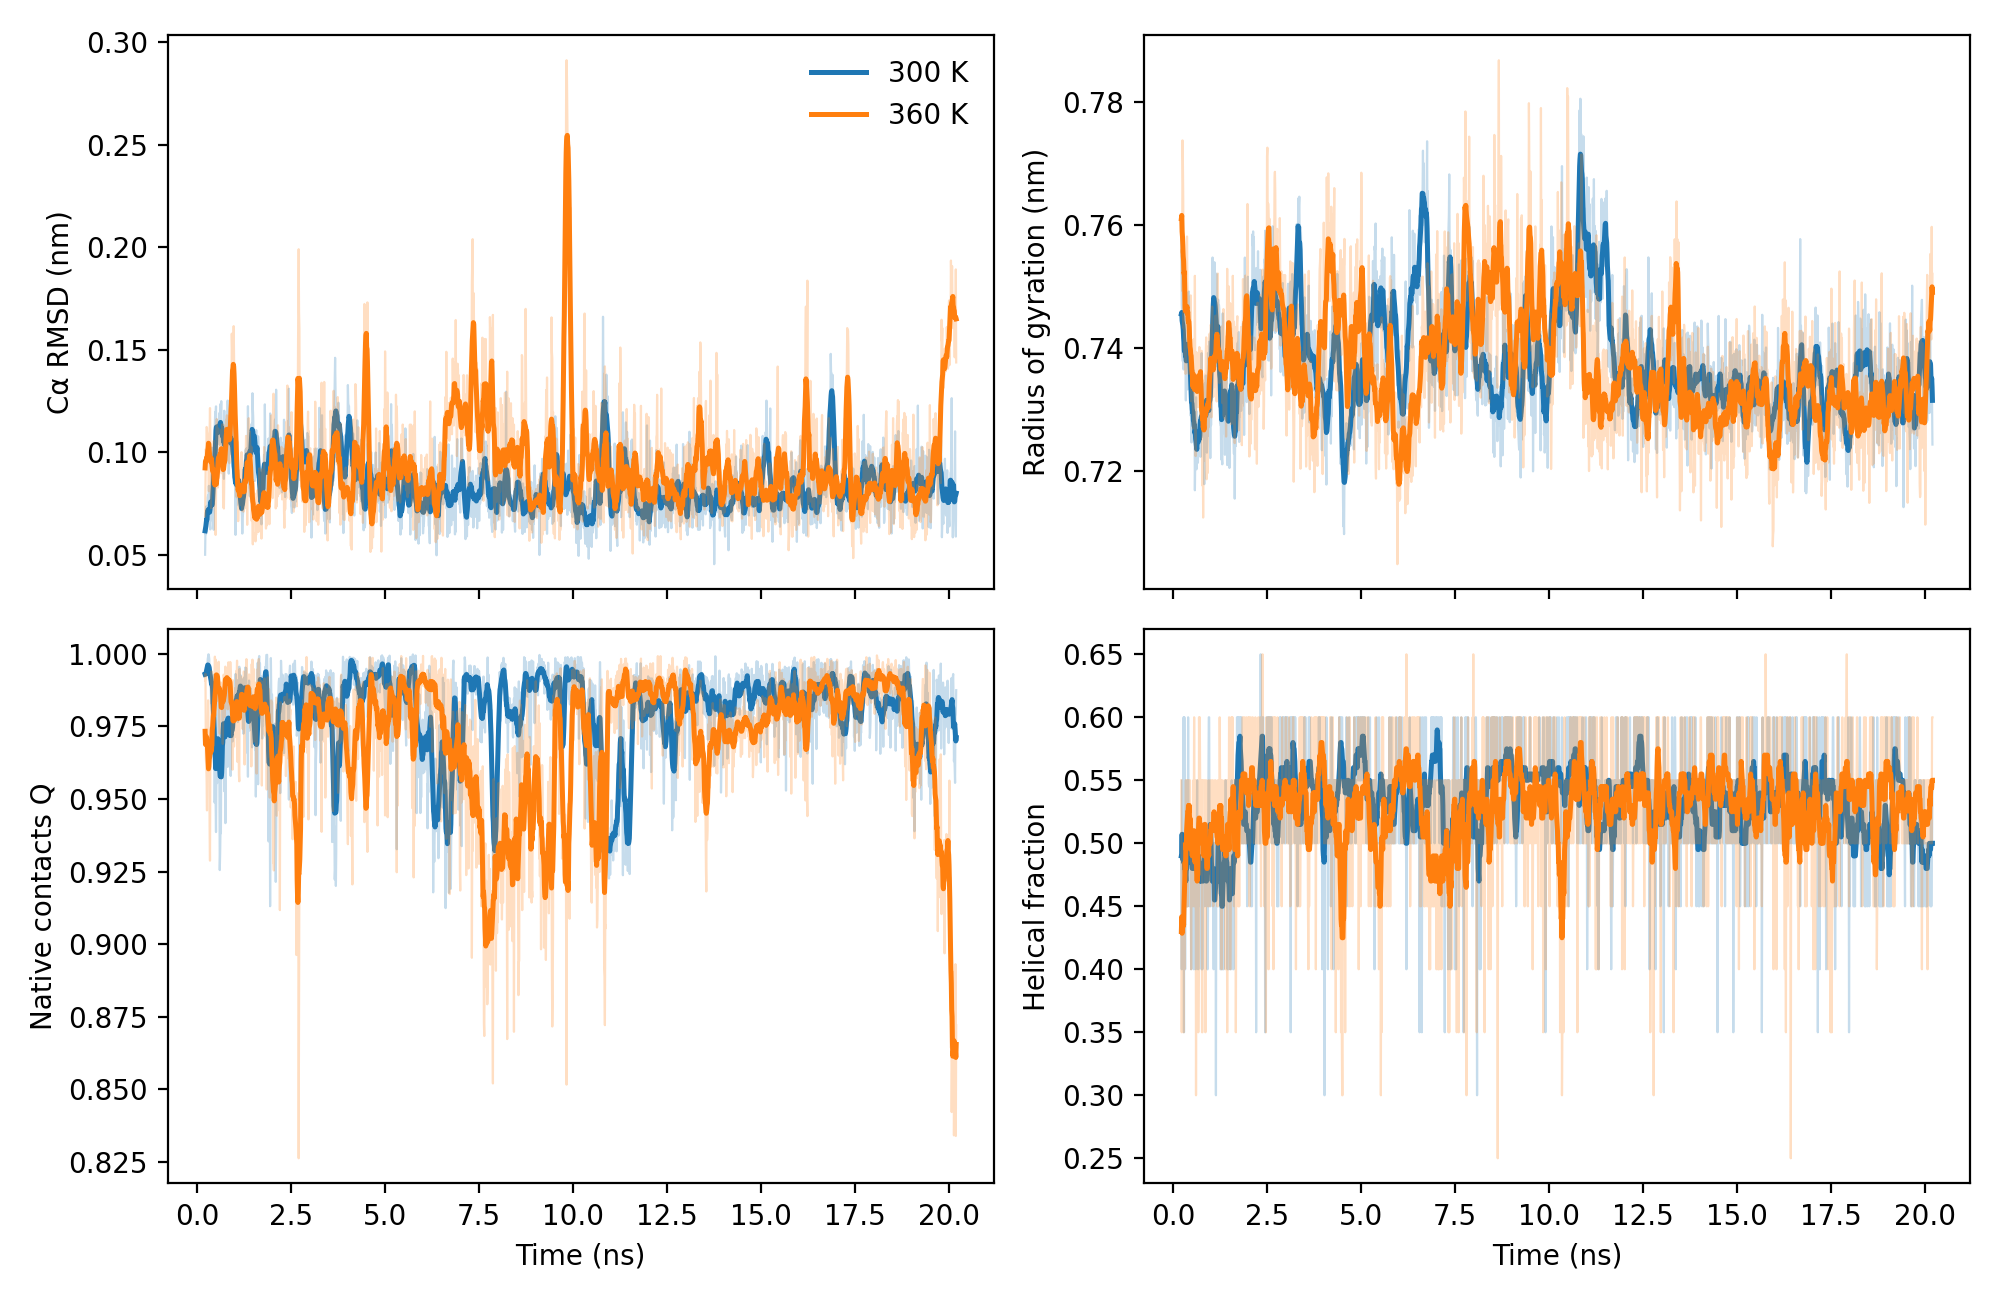

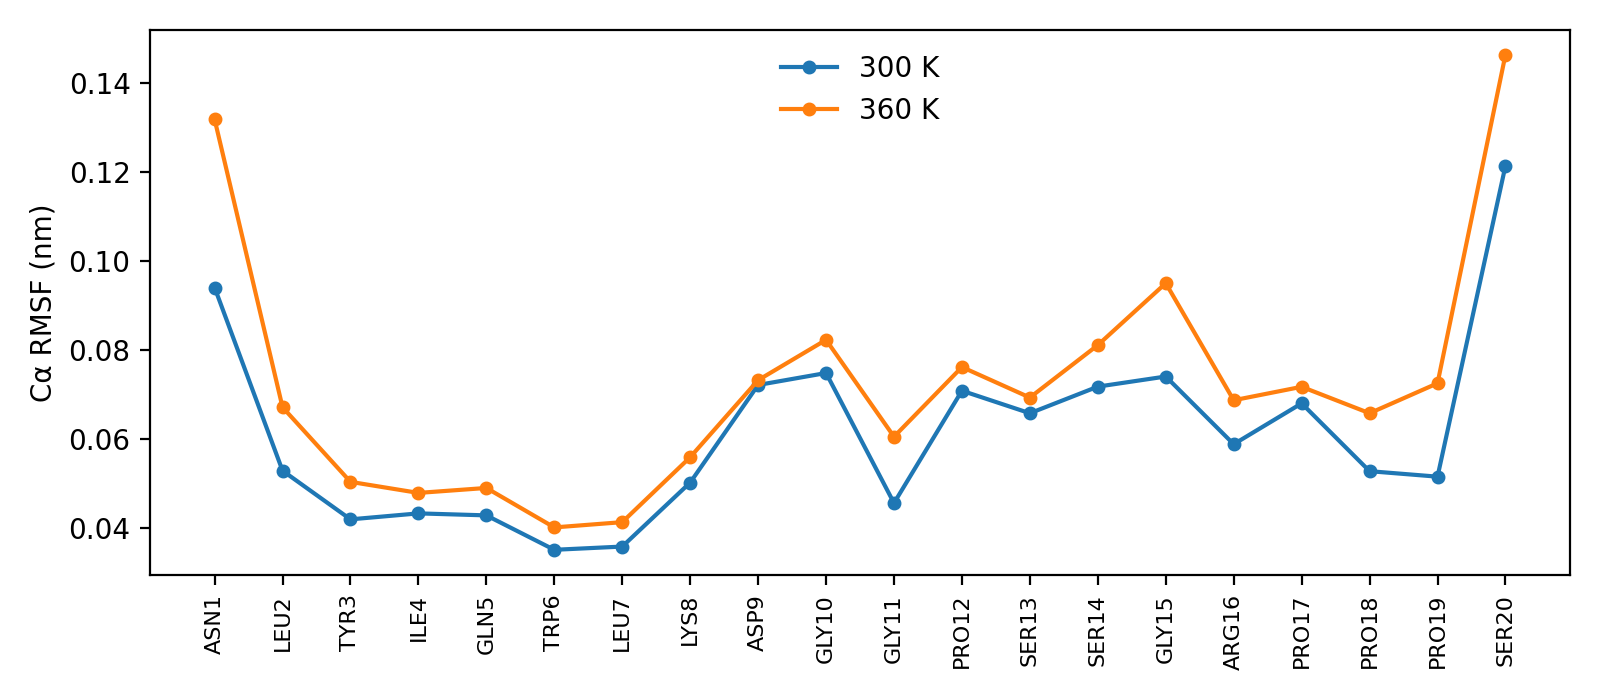

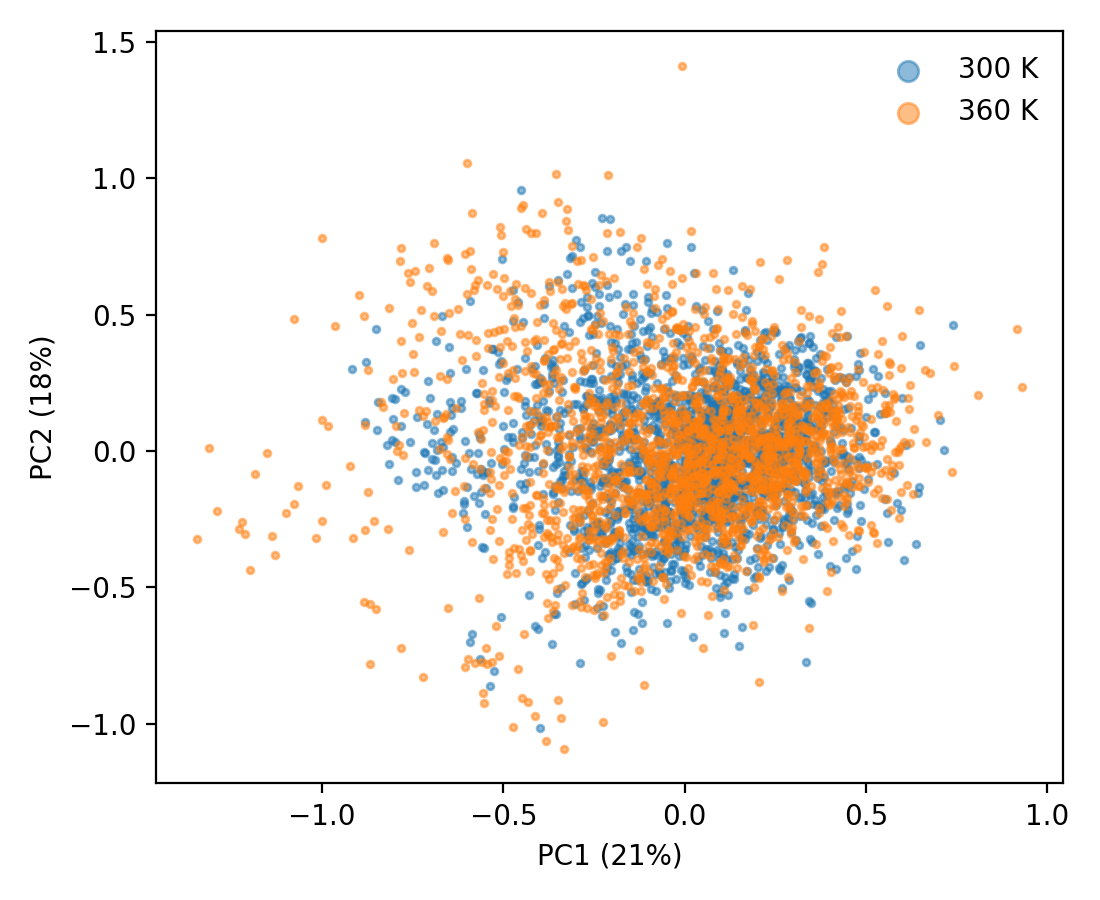

In [10]:
from IPython.display import Image, display
for f in ['timeseries', 'rmsf', 'pca']:
    display(Image(f'results/{f}.png', width=750))

## 10. Ensemble-level analysis

The basic descriptors show *that* the two ensembles differ only slightly. This section asks *how* they differ, *whether* the differences are statistically meaningful, and *whether* the simulation agrees with experiment. `analyze_advanced.py` discards the first 2 ns of each run as relaxation (the R<sub>g</sub> drift in section 9 settles by then) and computes the following:

| Analysis | Method | Question it answers |
|---|---|---|
| **10.1 Uncertainties** | Block averaging (10 blocks of 1.8 ns) with a convergence check of SEM against block length; Welch *t*-test on block means | Which differences between temperatures are real? |
| **10.2 Free-energy landscapes** | F(Q, R<sub>g</sub>) and F(PC1, PC2) = −k<sub>B</sub>T ln P, from 2D histograms | Is there one basin or several, and how does heating reshape it? |
| **10.3 NMR validation** | Cα RMSF and RMSD to model 1, compared with the 38-model NMR ensemble of 1L2Y | Are the simulated fluctuations realistic? |
| **10.4 Excursion mechanism** | Frames with Q < 0.92; contacts lost in those frames; Asp9–Arg16 salt-bridge distance (carboxylate O to guanidinium N, formed if < 0.40 nm); Q recomputed without Asp9/Arg16 contacts | What breaks when native contacts are lost? |
| **10.5 Core and contacts** | Trp6 side-chain SASA (Shrake–Rupley); residue contact maps (closest heavy atoms < 0.45 nm) | Does the hydrophobic cage open? Which contacts weaken with temperature? |
| **10.6 Interpretable classifier** | L2-regularized logistic regression on the 190 standardized Cα–Cα distances; cross-validation on 5 contiguous time blocks per run, so correlated neighbouring frames never appear in both training and test sets | Can the ensembles be told apart, and by which distances? |

The script also accepts several replicas per temperature (`--group 300 runs/T300 runs/T300_r2 ...`). In that case, uncertainties come from the spread between replicas and the classifier is validated with leave-one-replica-out cross-validation.

In [ ]:
%%writefile analyze_advanced.py
"""
analyze_advanced.py - ensemble-level analysis of Trp-cage MD simulations.

Groups of runs (one group per temperature; one or more replicas per group) are
compared with:
  1. free-energy landscapes  F(Q, Rg) and F(PC1, PC2),  F = -kT ln P
  2. validation against the experimental NMR ensemble (1L2Y, 38 models)
  3. an interpretable classifier (logistic regression on C-alpha distances)
     that identifies which inter-residue distances distinguish the ensembles
  4. Trp6 side-chain SASA, residue contact maps and the contacts broken
     during low-Q excursions
  5. block-averaged uncertainties and a Welch t-test between groups

Example:
    python analyze_advanced.py --group 300 runs/T300 --group 360 runs/T360 \
        --nmr 1L2Y.pdb --out results_advanced
With replicas, list several run directories after each temperature:
    --group 300 runs/T300 runs/T300_r2 runs/T300_r3
"""
import argparse
import itertools
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mdtraj as md
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from analyze import native_contacts_q


def native_contacts_q_excluding(traj, native, exclude_resseq):
    """Q (Best-Hummer-Eaton) computed without native contacts that involve the given residues."""
    beta, lam, cutoff = 50.0, 1.8, 0.45
    top = native.topology
    heavy = top.select_atom_indices("heavy")
    pairs = np.array([(i, j) for i, j in itertools.combinations(heavy, 2)
                      if abs(top.atom(i).residue.index - top.atom(j).residue.index) > 3
                      and top.atom(i).residue.resSeq not in exclude_resseq
                      and top.atom(j).residue.resSeq not in exclude_resseq])
    r0 = md.compute_distances(native[0], pairs)[0]
    pairs, r0 = pairs[r0 < cutoff], r0[r0 < cutoff]
    r = md.compute_distances(traj, pairs)
    return np.mean(1.0 / (1 + np.exp(beta * (r - lam * r0))), axis=1)

KB = 0.0083144626                       # Boltzmann constant, kJ mol^-1 K^-1
COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"]   # fixed order per group
CONTACT_CUTOFF = 0.45                   # nm, closest heavy-atom residue contact
METRICS = {"rmsd_nm": "Cα RMSD (nm)", "rg_nm": "R$_g$ (nm)", "Q": "Q",
           "helix_frac": "Helical fraction", "trp6_sasa_nm2": "Trp6 SASA (nm²)",
           "sb_d9_r16_nm": "Asp9–Arg16 distance (nm)"}
SALT_BRIDGE_CUTOFF = 0.40               # nm, carboxylate O - guanidinium N

plt.rcParams.update({"font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.dpi": 200})


# --------------------------------------------------------------------------- #
# Per-run features
# --------------------------------------------------------------------------- #
def residue_label(res):
    return f"{res.code}{res.resSeq}"


def load_run(path, skip_ns):
    ref = md.load(os.path.join(path, "protein_start.pdb"))
    traj = md.load(os.path.join(path, "protein.xtc"), top=ref)
    t_ns = (traj.time - traj.time[0]) / 1000.0
    traj = traj[t_ns >= skip_ns]
    t_ns = t_ns[t_ns >= skip_ns]

    ca = traj.topology.select("name CA")
    traj.superpose(ref, atom_indices=ca)
    dssp = md.compute_dssp(traj, simplified=True)       # 'H' = alpha, 3-10, pi helix
    sasa = md.shrake_rupley(traj, mode="residue", n_sphere_points=240)
    trp = [r.index for r in traj.topology.residues if r.name == "TRP"][0]
    cdist, cpairs = md.compute_contacts(traj, contacts="all", scheme="closest-heavy")
    pair_idx = np.array(list(itertools.combinations(ca, 2)))

    # Asp9-Arg16 salt bridge: minimum O(Asp9 side chain) - N(Arg16 side chain) distance
    o = traj.topology.select("resSeq 9 and resname ASP and name OD1 OD2")
    n = traj.topology.select("resSeq 16 and resname ARG and name NE NH1 NH2")
    sb = md.compute_distances(traj, np.array([(i, j) for i in o for j in n])).min(axis=1)

    xyz = traj.xyz[:, ca, :]
    rmsf = np.sqrt(((xyz - xyz.mean(axis=0)) ** 2).sum(axis=2).mean(axis=0))

    df = pd.DataFrame({
        "time_ns": t_ns,
        "rmsd_nm": md.rmsd(traj, ref, atom_indices=ca),
        "rg_nm": md.compute_rg(traj),
        "Q": native_contacts_q(traj, ref),
        "helix_frac": (dssp == "H").mean(axis=1),
        "trp6_sasa_nm2": sasa[:, trp],
        "sb_d9_r16_nm": sb,
        "Q_excl_d9_r16": native_contacts_q_excluding(traj, ref, {9, 16}),
    })
    return {"path": path, "traj": traj, "df": df, "rmsf": rmsf,
            "ca_dist": md.compute_distances(traj, pair_idx),
            "ca_pairs": pair_idx, "contacts": cdist < CONTACT_CUTOFF,
            "contact_pairs": cpairs, "ca": ca}


# --------------------------------------------------------------------------- #
# Statistics
# --------------------------------------------------------------------------- #
def block_means(x, n_blocks):
    n = len(x) // n_blocks
    return np.array([x[i * n:(i + 1) * n].mean() for i in range(n_blocks)])


def block_sem(x, n_blocks):
    b = block_means(x, n_blocks)
    return b.std(ddof=1) / np.sqrt(n_blocks)


def sem_vs_block_length(x, dt_ns):
    """Standard error of the mean as a function of block length (Flyvbjerg-Petersen style)."""
    lengths, sems = [], []
    for nb in range(len(x) // 4, 3, -1):
        size = len(x) // nb
        if lengths and size == lengths[-1]:
            continue
        lengths.append(size)
        sems.append(block_sem(x, nb))
    return np.array(lengths) * dt_ns, np.array(sems)


def group_summary(runs, n_blocks):
    """Mean, SEM and s.d. per metric. SEM from replicas if >= 2, else from blocks."""
    out = {}
    for m in METRICS:
        per_run = [r["df"][m].values for r in runs]
        pooled = np.concatenate(per_run)
        if len(runs) >= 2:
            means = np.array([x.mean() for x in per_run])
            sem = means.std(ddof=1) / np.sqrt(len(means))
        else:
            sem = block_sem(per_run[0], n_blocks)
        out[m] = {"mean": pooled.mean(), "sem": sem, "sd": pooled.std(ddof=1)}
    q = np.concatenate([r["df"]["Q"].values for r in runs])
    sbf = [(r["df"]["sb_d9_r16_nm"].values < SALT_BRIDGE_CUTOFF).astype(float) for r in runs]
    out["salt_bridge_formed"] = {"mean": float(np.concatenate(sbf).mean()), "sem": float(
        np.std(np.concatenate([block_means(x, n_blocks) for x in sbf]), ddof=1)
        / np.sqrt(n_blocks * len(runs)))}
    out["p_Q_below_0.9"] = {"mean": float((q < 0.9).mean()), "sem": float(
        np.std([block_means((r["df"]["Q"].values < 0.9).astype(float), n_blocks)
                for r in runs], ddof=1) / np.sqrt(n_blocks * len(runs)))}
    return out


# --------------------------------------------------------------------------- #
# Figures
# --------------------------------------------------------------------------- #
def free_energy(x, y, T, bins, xr, yr):
    H, xe, ye = np.histogram2d(x, y, bins=bins, range=[xr, yr], density=True)
    with np.errstate(divide="ignore"):
        F = -KB * T * np.log(H)
    F -= np.nanmin(F[np.isfinite(F)])
    F[~np.isfinite(F)] = np.nan
    return F.T, xe, ye


def plot_fes(groups, xkey, ykey, xlabel, ylabel, fname, out, data=None, fmax=12.0):
    xs = {g: (data[g][0] if data else np.concatenate([r["df"][xkey] for r in runs]))
          for g, runs in groups.items()}
    ys = {g: (data[g][1] if data else np.concatenate([r["df"][ykey] for r in runs]))
          for g, runs in groups.items()}
    allx, ally = np.concatenate(list(xs.values())), np.concatenate(list(ys.values()))
    pad_x, pad_y = 0.02 * np.ptp(allx), 0.02 * np.ptp(ally)
    xr = (allx.min() - pad_x, allx.max() + pad_x)
    yr = (ally.min() - pad_y, ally.max() + pad_y)

    fig, axes = plt.subplots(1, len(groups), figsize=(3.6 * len(groups) + 0.8, 3.4),
                             sharex=True, sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    levels = np.linspace(0, fmax, 13)
    for ax, (T, runs) in zip(axes, groups.items()):
        F, xe, ye = free_energy(xs[T], ys[T], T, 30, xr, yr)
        xc, yc = 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1])
        cf = ax.contourf(xc, yc, np.clip(F, 0, fmax), levels=levels, cmap="Blues_r",
                         extend="max")
        ax.contour(xc, yc, F, levels=levels[::3], colors="k", linewidths=0.4)
        ax.set_title(f"{T:.0f} K")
        ax.set_xlabel(xlabel)
    axes[0].set_ylabel(ylabel)
    fig.colorbar(cf, ax=axes, label="F (kJ mol$^{-1}$)", shrink=0.9)
    fig.savefig(os.path.join(out, fname))
    plt.close(fig)


# --------------------------------------------------------------------------- #
def main():
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--group", nargs="+", action="append", required=True,
                    metavar=("TEMP_K", "RUN_DIR"),
                    help="temperature in K followed by one or more run directories")
    ap.add_argument("--nmr", default="1L2Y.pdb", help="experimental NMR ensemble")
    ap.add_argument("--skip_ns", type=float, default=2.0,
                    help="initial relaxation discarded from every run (ns)")
    ap.add_argument("--blocks", type=int, default=10, help="blocks for error estimates")
    ap.add_argument("--q_excursion", type=float, default=0.92,
                    help="Q threshold that defines a non-native excursion")
    ap.add_argument("--out", default="results_advanced")
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)

    groups = {}
    for spec in args.group:
        T = float(spec[0])
        groups[T] = [load_run(p, args.skip_ns) for p in spec[1:]]
        print(f"{T:.0f} K: {len(spec) - 1} run(s), "
              f"{sum(len(r['df']) for r in groups[T])} frames after {args.skip_ns} ns skip")
    temps = list(groups)
    color = {T: COLORS[i] for i, T in enumerate(temps)}
    first = groups[temps[0]][0]
    top = first["traj"].topology
    labels = [residue_label(r) for r in top.residues]
    report = {"skip_ns": args.skip_ns}

    # ---- 5. Block-averaged summary + Welch t-test --------------------------
    summ = {T: group_summary(runs, args.blocks) for T, runs in groups.items()}
    rows = []
    for T in temps:
        row = {"T_K": T, "n_runs": len(groups[T]),
               "ns_analysed": round(sum(np.ptp(r["df"].time_ns.values) for r in groups[T]), 1)}
        for m, v in summ[T].items():
            row.update({f"{m}_mean": v["mean"], f"{m}_sem": v["sem"]})
            if "sd" in v:
                row[f"{m}_sd"] = v["sd"]
        rows.append(row)
    pd.DataFrame(rows).to_csv(os.path.join(args.out, "summary_advanced.csv"), index=False)
    report["summary"] = {f"{T:.0f}": summ[T] for T in temps}

    if len(temps) >= 2:
        a, b = temps[0], temps[1]
        tests = {}
        for m in METRICS:
            ba = np.concatenate([block_means(r["df"][m].values, args.blocks) for r in groups[a]])
            bb = np.concatenate([block_means(r["df"][m].values, args.blocks) for r in groups[b]])
            t, p = stats.ttest_ind(bb, ba, equal_var=False)
            tests[m] = {"diff": float(bb.mean() - ba.mean()), "p": float(p)}
        report["welch_block_means"] = tests

    # block-length convergence for Q and RMSD
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8), constrained_layout=True)
    for ax, m in zip(axes, ["Q", "rmsd_nm"]):
        for T in temps:
            for k, r in enumerate(groups[T]):
                dt = np.median(np.diff(r["df"].time_ns))
                L, s = sem_vs_block_length(r["df"][m].values, dt)
                ax.plot(L, s, color=color[T], lw=1.5, alpha=1 if k == 0 else 0.5,
                        label=f"{T:.0f} K" if k == 0 else None)
        ax.set_xlabel("Block length (ns)")
        ax.set_ylabel(f"SEM of {METRICS[m]}")
    axes[0].legend(frameon=False)
    fig.savefig(os.path.join(args.out, "block_convergence.png"))
    plt.close(fig)

    # ---- 1. Free-energy landscapes ------------------------------------------
    plot_fes(groups, "Q", "rg_nm", "Native contacts Q", "R$_g$ (nm)", "fes_Q_Rg.png", args.out)
    X_all = np.vstack([r["ca_dist"] for T in temps for r in groups[T]])
    pca = PCA(n_components=2).fit(X_all)
    pc = {T: np.vstack([pca.transform(r["ca_dist"]) for r in groups[T]]) for T in temps}
    ev = pca.explained_variance_ratio_ * 100
    plot_fes(groups, None, None, f"PC1 ({ev[0]:.0f}%)", f"PC2 ({ev[1]:.0f}%)",
             "fes_pca.png", args.out, data={T: (pc[T][:, 0], pc[T][:, 1]) for T in temps})
    report["pca_explained_pct"] = ev.round(1).tolist()

    # ---- 2. Validation against the NMR ensemble ----------------------------
    if os.path.exists(args.nmr):
        nmr = md.load(args.nmr)
        nmr_ca = nmr.atom_slice(nmr.topology.select("name CA"))
        nmr_ca.superpose(nmr_ca, 0)
        nmr_rmsd = md.rmsd(nmr_ca, nmr_ca, 0)[1:]                 # models 2-38 vs model 1
        mean_xyz = nmr_ca.xyz.mean(axis=0)
        nmr_rmsf = np.sqrt(((nmr_ca.xyz - mean_xyz) ** 2).sum(axis=2).mean(axis=0))

        fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), constrained_layout=True,
                                 gridspec_kw={"width_ratios": [1.6, 1]})
        x = np.arange(len(labels))
        axes[0].plot(x, nmr_rmsf, "k--", marker="s", ms=3, lw=1.2, label=f"NMR ensemble ({nmr.n_frames} models)")
        val = {"nmr_rmsd_to_model1_nm": {"min": float(nmr_rmsd.min()),
                                         "median": float(np.median(nmr_rmsd)),
                                         "max": float(nmr_rmsd.max())}}
        for T in temps:
            md_rmsf = np.mean([r["rmsf"] for r in groups[T]], axis=0)
            r_corr = stats.pearsonr(md_rmsf, nmr_rmsf)[0]
            axes[0].plot(x, md_rmsf, marker="o", ms=3, lw=1.5, color=color[T],
                         label=f"MD {T:.0f} K (r = {r_corr:.2f})")
            traj_ca = np.vstack([r["traj"].atom_slice(r["ca"]).xyz for r in groups[T]])
            md_ca = md.Trajectory(traj_ca, nmr_ca.topology)
            md_rmsd = md.rmsd(md_ca, nmr_ca, 0)
            axes[1].hist(md_rmsd, bins=40, density=True, histtype="step", lw=1.5,
                         color=color[T], label=f"MD {T:.0f} K")
            val[f"{T:.0f}"] = {"rmsf_pearson_r": float(r_corr),
                               "md_rmsd_to_model1_median_nm": float(np.median(md_rmsd)),
                               "frac_within_nmr_range": float((md_rmsd <= nmr_rmsd.max()).mean())}
        axes[0].set_xticks(x)
        axes[0].set_xticklabels(labels, fontsize=7)
        axes[0].set_ylabel("Cα RMSF (nm)")
        axes[0].legend(frameon=False, fontsize=7)
        ymax = axes[1].get_ylim()[1]
        axes[1].plot(nmr_rmsd, np.full_like(nmr_rmsd, ymax * 0.03), "k|", ms=10,
                     label="NMR models vs model 1")
        axes[1].set_xlabel("Cα RMSD to NMR model 1 (nm)")
        axes[1].set_ylabel("Probability density")
        axes[1].legend(frameon=False, fontsize=7)
        fig.savefig(os.path.join(args.out, "nmr_validation.png"))
        plt.close(fig)
        report["nmr_validation"] = val
    else:
        print(f"NMR file {args.nmr} not found - skipping validation")

    # ---- 3. Interpretable classifier ---------------------------------------
    if len(temps) == 2:
        runs_flat = [(i, k, r) for i, T in enumerate(temps) for k, r in enumerate(groups[T])]
        X = np.vstack([r["ca_dist"] for _, _, r in runs_flat])
        y = np.concatenate([np.full(len(r["df"]), i) for i, _, r in runs_flat])
        n_rep = min(len(groups[T]) for T in temps)
        if n_rep >= 2:          # leave one replica of each temperature out
            fold = np.concatenate([np.full(len(r["df"]), k % n_rep) for _, k, r in runs_flat])
            n_folds, cv_kind = n_rep, "leave-one-replica-out"
        else:                   # contiguous time blocks (avoids leaking correlated frames)
            n_folds, cv_kind = 5, "5 contiguous time blocks per run"
            fold = np.concatenate([np.minimum(np.arange(len(r["df"])) * 5 // len(r["df"]), 4)
                                   for _, _, r in runs_flat])
        model = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000))
        accs = []
        for k in range(n_folds):
            tr, te = fold != k, fold == k
            model.fit(X[tr], y[tr])
            accs.append(balanced_accuracy_score(y[te], model.predict(X[te])))
        model.fit(X, y)
        coef = model[-1].coef_[0]
        order = np.argsort(-np.abs(coef))[:12]
        pair_res = [(top.atom(i).residue, top.atom(j).residue) for i, j in first["ca_pairs"]]
        names = [f"{residue_label(a)}–{residue_label(b)}" for a, b in pair_res]
        d_mean = {i: X[y == i].mean(axis=0) for i in (0, 1)}

        fig, ax = plt.subplots(figsize=(5.2, 3.6), constrained_layout=True)
        yy = np.arange(len(order))[::-1]
        ax.barh(yy, coef[order], color=[color[temps[1]] if c > 0 else color[temps[0]]
                                        for c in coef[order]], height=0.6)
        ax.set_yticks(yy)
        ax.set_yticklabels([names[i] for i in order])
        ax.axvline(0, color="0.4", lw=0.8)
        ax.set_xlabel(f"Standardized coefficient  (+ = longer at {temps[1]:.0f} K)")
        ax.set_title(f"Balanced accuracy {np.mean(accs):.2f} ± {np.std(accs):.2f} ({cv_kind})",
                     fontsize=8)
        fig.savefig(os.path.join(args.out, "classifier_features.png"))
        plt.close(fig)
        report["classifier"] = {
            "cv": cv_kind, "balanced_accuracy_folds": [round(a, 3) for a in accs],
            "balanced_accuracy_mean": float(np.mean(accs)),
            "top_features": [{"pair": names[i], "coef": float(coef[i]),
                              f"mean_dist_{temps[0]:.0f}K_nm": float(d_mean[0][i]),
                              f"mean_dist_{temps[1]:.0f}K_nm": float(d_mean[1][i])}
                             for i in order[:6]]}

    # ---- 4. Trp6 SASA, contact maps, excursion contacts ---------------------
    fig, axes = plt.subplots(1, 2, figsize=(9, 3), constrained_layout=True,
                             gridspec_kw={"width_ratios": [2, 1]})
    for T in temps:
        for k, r in enumerate(groups[T]):
            s = pd.Series(r["df"].trp6_sasa_nm2).rolling(20, center=True, min_periods=1).mean()
            axes[0].plot(r["df"].time_ns, s, color=color[T], lw=1,
                         alpha=1 if k == 0 else 0.5, label=f"{T:.0f} K" if k == 0 else None)
        allv = np.concatenate([r["df"].trp6_sasa_nm2 for r in groups[T]])
        axes[1].hist(allv, bins=40, density=True, histtype="step", lw=1.5, color=color[T],
                     label=f"{T:.0f} K")
    axes[0].set_xlabel("Time (ns)")
    axes[0].set_ylabel("Trp6 SASA (nm²)")
    axes[0].legend(frameon=False)
    axes[1].set_xlabel("Trp6 SASA (nm²)")
    axes[1].set_ylabel("Probability density")
    fig.savefig(os.path.join(args.out, "trp6_sasa.png"))
    plt.close(fig)

    n_res = top.n_residues
    cpairs = first["contact_pairs"]
    freq = {}
    for T in temps:
        f = np.concatenate([r["contacts"] for r in groups[T]]).mean(axis=0)
        M = np.full((n_res, n_res), np.nan)
        M[cpairs[:, 0], cpairs[:, 1]] = f
        M[cpairs[:, 1], cpairs[:, 0]] = f
        freq[T] = M
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
    im0 = axes[0].imshow(freq[temps[0]], cmap="Blues", vmin=0, vmax=1, origin="lower")
    axes[0].set_title(f"Contact frequency, {temps[0]:.0f} K")
    fig.colorbar(im0, ax=axes[0], shrink=0.8)
    if len(temps) >= 2:
        D = freq[temps[1]] - freq[temps[0]]
        lim = max(0.05, np.nanmax(np.abs(D)))
        im1 = axes[1].imshow(D, cmap="RdBu_r", vmin=-lim, vmax=lim, origin="lower")
        axes[1].set_title(f"Difference, {temps[1]:.0f} K − {temps[0]:.0f} K")
        fig.colorbar(im1, ax=axes[1], shrink=0.8)
    for ax in axes:
        ax.set_xticks(range(n_res))
        ax.set_yticks(range(n_res))
        ax.set_xticklabels(labels, rotation=90, fontsize=6)
        ax.set_yticklabels(labels, fontsize=6)
    fig.savefig(os.path.join(args.out, "contact_maps.png"))
    plt.close(fig)

    pair_names = [f"{labels[i]}–{labels[j]}" for i, j in cpairs]
    if len(temps) >= 2:
        D = freq[temps[1]][cpairs[:, 0], cpairs[:, 1]] - freq[temps[0]][cpairs[:, 0], cpairs[:, 1]]
        idx = np.argsort(D)[:5]
        report["largest_contact_loss_at_high_T"] = [
            {"pair": pair_names[i], "freq_low_T": float(freq[temps[0]][tuple(cpairs[i])]),
             "freq_high_T": float(freq[temps[1]][tuple(cpairs[i])])} for i in idx]

    exc = {}
    for T in temps:
        q = np.concatenate([r["df"].Q.values for r in groups[T]])
        C = np.concatenate([r["contacts"] for r in groups[T]])
        low = q < args.q_excursion
        if low.sum() >= 5:
            drop = C[~low].mean(axis=0) - C[low].mean(axis=0)
            idx = np.argsort(-drop)[:5]
            # excursion events: contiguous low-Q stretches per run
            events = []
            for r in groups[T]:
                lo = (r["df"].Q.values < args.q_excursion).astype(int)
                starts = np.flatnonzero(np.diff(np.r_[0, lo]) == 1)
                ends = np.flatnonzero(np.diff(np.r_[lo, 0]) == -1)
                events += [{"run": r["path"], "start_ns": float(r["df"].time_ns.iloc[s]),
                            "end_ns": float(r["df"].time_ns.iloc[e]),
                            "min_Q": float(r["df"].Q.values[s:e + 1].min())}
                           for s, e in zip(starts, ends) if e - s >= 4]
            exc[f"{T:.0f}"] = {
                "fraction_frames": float(low.mean()),
                "events_ge_5_frames": sorted(events, key=lambda e: e["min_Q"])[:6],
                "contacts_broken": [{"pair": pair_names[i],
                                     "freq_native_like": float(C[~low, i].mean()),
                                     "freq_excursion": float(C[low, i].mean())} for i in idx]}
        else:
            exc[f"{T:.0f}"] = {"fraction_frames": float(low.mean())}
    report["excursions_Q_below"] = {"threshold": args.q_excursion, **exc}

    # Asp9-Arg16 salt bridge vs native contacts
    fig, axes = plt.subplots(3, 1, figsize=(8, 6.2), sharex=True, constrained_layout=True)
    sb_rep = {}
    for T in temps:
        for k, r in enumerate(groups[T]):
            d = r["df"]
            sm = lambda v: pd.Series(v).rolling(10, center=True, min_periods=1).mean()
            kw = dict(color=color[T], lw=1, alpha=1 if k == 0 else 0.5,
                      label=f"{T:.0f} K" if k == 0 else None)
            axes[0].plot(d.time_ns, sm(d.Q), **kw)
            axes[1].plot(d.time_ns, sm(d.Q_excl_d9_r16), **kw)
            axes[2].plot(d.time_ns, sm(d.sb_d9_r16_nm), **kw)
        q = np.concatenate([r["df"].Q.values for r in groups[T]])
        sbd = np.concatenate([r["df"].sb_d9_r16_nm.values for r in groups[T]])
        low = q < args.q_excursion
        broken = sbd >= SALT_BRIDGE_CUTOFF
        qx = np.concatenate([r["df"].Q_excl_d9_r16.values for r in groups[T]])
        sb_rep[f"{T:.0f}"] = {
            "corr_Qexcl_vs_distance": float(stats.pearsonr(qx, sbd)[0]),
            "frac_Qexcl_below_threshold": float((qx < args.q_excursion).mean()),
            "Qexcl_mean": float(qx.mean()),
            "p_broken": float(broken.mean()),
            "p_broken_given_excursion": float(broken[low].mean()) if low.any() else None,
            "p_broken_given_native": float(broken[~low].mean()),
            "corr_Q_vs_distance": float(stats.pearsonr(q, sbd)[0])}
    axes[0].axhline(args.q_excursion, color="0.5", ls=":", lw=1)
    axes[0].set_ylabel("Q")
    axes[0].legend(frameon=False, ncol=2)
    axes[1].axhline(args.q_excursion, color="0.5", ls=":", lw=1)
    axes[1].set_ylabel("Q without\nAsp9/Arg16 contacts")
    axes[1].set_ylim(axes[0].get_ylim())
    axes[2].axhline(SALT_BRIDGE_CUTOFF, color="0.5", ls=":", lw=1)
    axes[2].set_ylabel("Asp9–Arg16 distance (nm)")
    axes[2].set_xlabel("Time (ns)")
    fig.savefig(os.path.join(args.out, "salt_bridge.png"))
    plt.close(fig)
    report["salt_bridge_D9_R16"] = {"cutoff_nm": SALT_BRIDGE_CUTOFF, **sb_rep}

    with open(os.path.join(args.out, "report.json"), "w") as fh:
        json.dump(report, fh, indent=2, default=float)

    # ---- console report -----------------------------------------------------
    pd.set_option("display.width", 200)
    plain = {**METRICS, "rg_nm": "Rg (nm)", "salt_bridge_formed": "Salt bridge formed (fraction)",
             "p_Q_below_0.9": "P(Q < 0.9)"}
    tab = pd.DataFrame({f"{T:.0f} K": {plain.get(m, m): f"{v['mean']:.3f} ± {v['sem']:.3f}"
                                       for m, v in summ[T].items()} for T in temps})
    print("\nMean ± SEM (", "replicas" if min(len(g) for g in groups.values()) >= 2
          else f"{args.blocks} blocks", ")\n", tab.to_string(), sep="")
    print("\nFull report:", os.path.join(args.out, "report.json"))


if __name__ == "__main__":
    main()


Writing analyze_advanced.py


In [ ]:
!python analyze_advanced.py --group 300 runs/T300 --group 360 runs/T360 --nmr 1L2Y.pdb --out results_advanced

300 K: 1 run(s), 1800 frames after 2.0 ns skip
360 K: 1 run(s), 1800 frames after 2.0 ns skip

Mean ± SEM (10 blocks)
                                       300 K          360 K
Cα RMSD (nm)                   0.083 ± 0.002  0.095 ± 0.002
Rg (nm)                        0.738 ± 0.002  0.737 ± 0.002
Q                              0.980 ± 0.002  0.970 ± 0.005
Helical fraction               0.535 ± 0.003  0.529 ± 0.003
Trp6 SASA (nm²)                0.203 ± 0.011  0.218 ± 0.010
Asp9–Arg16 distance (nm)       0.359 ± 0.026  0.356 ± 0.029
Salt bridge formed (fraction)  0.757 ± 0.079  0.778 ± 0.078
P(Q < 0.9)                     0.000 ± 0.000  0.028 ± 0.014

Full report: results_advanced/report.json


In [ ]:
import json
from IPython.display import Image, display
report = json.load(open('results_advanced/report.json'))
print(json.dumps(report['welch_block_means'], indent=1))

{
 "rmsd_nm": {
  "diff": 0.011868372559547424,
  "p": 0.0009983365889638662
 },
 "rg_nm": {
  "diff": -0.0008866563745079103,
  "p": 0.7350404247136871
 },
 "Q": {
  "diff": -0.010552287101745605,
  "p": 0.08063672482967377
 },
 "helix_frac": {
  "diff": -0.005305555555555674,
  "p": 0.2400693312023476
 },
 "trp6_sasa_nm2": {
  "diff": 0.014355778694152832,
  "p": 0.35533857345581055
 },
 "sb_d9_r16_nm": {
  "diff": -0.003328263759613037,
  "p": 0.9329215288162231
 }
}


### 10.1 Statistical comparison

Mean ± SEM (block averaging, 10 blocks of 1.8 ns, t = 2–20 ns). The *p*-values are from a Welch *t*-test on block means.

| Descriptor | 300 K | 360 K | *p* |
|---|---|---|---|
| Cα RMSD (nm) | 0.083 ± 0.002 | 0.095 ± 0.002 | < 0.001 |
| R<sub>g</sub> (nm) | 0.738 ± 0.002 | 0.737 ± 0.002 | 0.74 |
| Native contacts Q | 0.980 ± 0.002 | 0.970 ± 0.005 | 0.08 |
| Helical fraction | 0.535 ± 0.003 | 0.529 ± 0.003 | 0.24 |
| Trp6 SASA (nm²) | 0.203 ± 0.011 | 0.218 ± 0.010 | 0.36 |
| Asp9–Arg16 salt bridge formed (fraction) | 0.76 ± 0.08 | 0.78 ± 0.08 | 0.93† |
| Fraction of frames with Q < 0.9 | 0.000 ± 0.000 | 0.028 ± 0.014 | – |

† Test on the salt-bridge distance.

Only the Cα RMSD differs significantly between the temperatures. The 360 K ensemble deviates about 0.01 nm more from the native structure, while compactness, helicity and burial of Trp6 are statistically indistinguishable. The small decrease in Q (p = 0.08) comes from rare, short excursions (2.8% of frames below Q = 0.9 at 360 K, none at 300 K), which section 10.4 examines.

**Convergence check.** The SEM of a correlated time series grows with block length until the blocks become independent. At 300 K the SEM of Q levels off at blocks of about 1–2 ns (the RMSD more slowly), so the quoted SEMs are reasonable estimates. At 360 K the SEM of Q is still rising at 4 ns blocks, because the excursions are rare and the salt bridge can stay in one state for several nanoseconds (section 10.4). The 360 K uncertainties should therefore be read as lower bounds, which is a quantitative argument for running replicas.

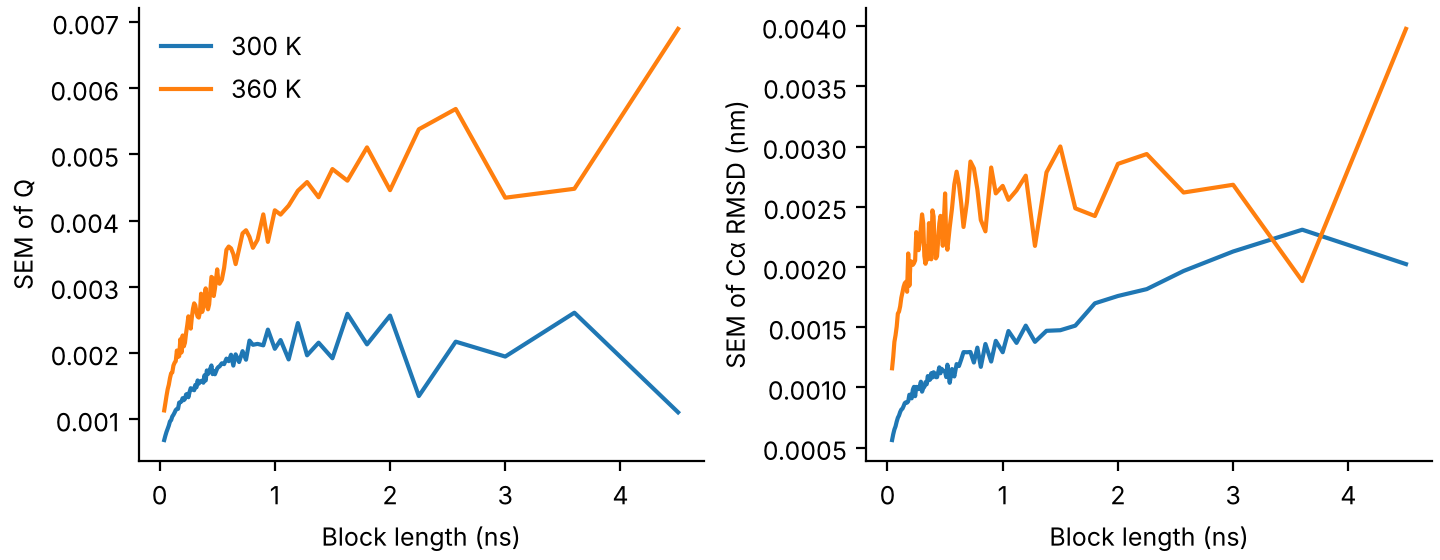

In [ ]:
display(Image('results_advanced/block_convergence.png', width=700))

### 10.2 Free-energy landscapes

F(Q, R<sub>g</sub>) shows a single native basin at both temperatures, centred at Q ≈ 0.99 and R<sub>g</sub> ≈ 0.73 nm. At 360 K the basin is broader and has a shallow shoulder that extends towards Q ≈ 0.85–0.90 at ≥ 8 kJ mol⁻¹ above the minimum. No second (unfolded) basin appears. The PCA landscape (PC1 and PC2 explain 22% and 19% of the variance in Cα–Cα distances) tells the same story: the 360 K distribution covers the same region as at 300 K, with sparse extra density at its edges.

*These landscapes come from one 18 ns trajectory per temperature, so their high-F regions are poorly sampled. They show the shape of the native basin, not converged free-energy differences.*

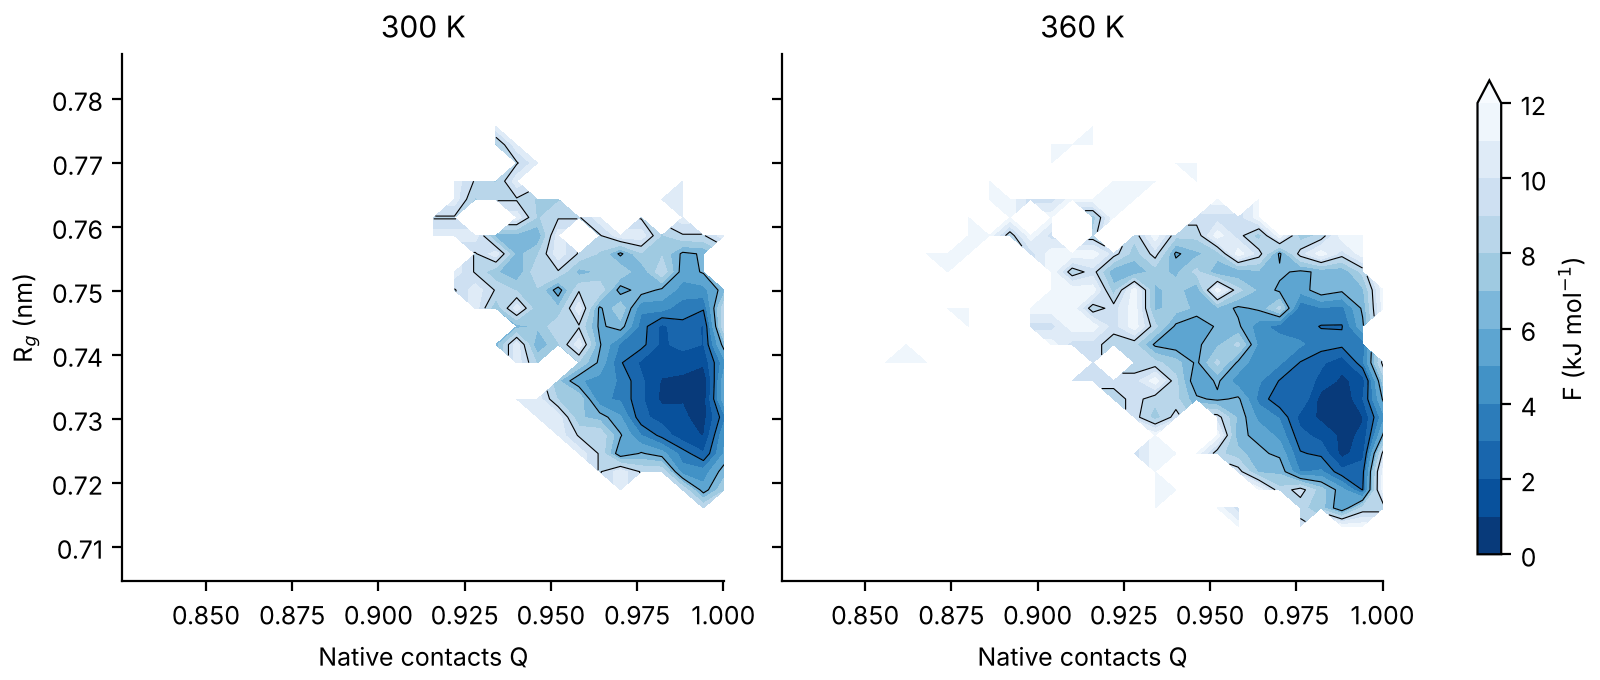

In [ ]:
display(Image('results_advanced/fes_Q_Rg.png', width=800))

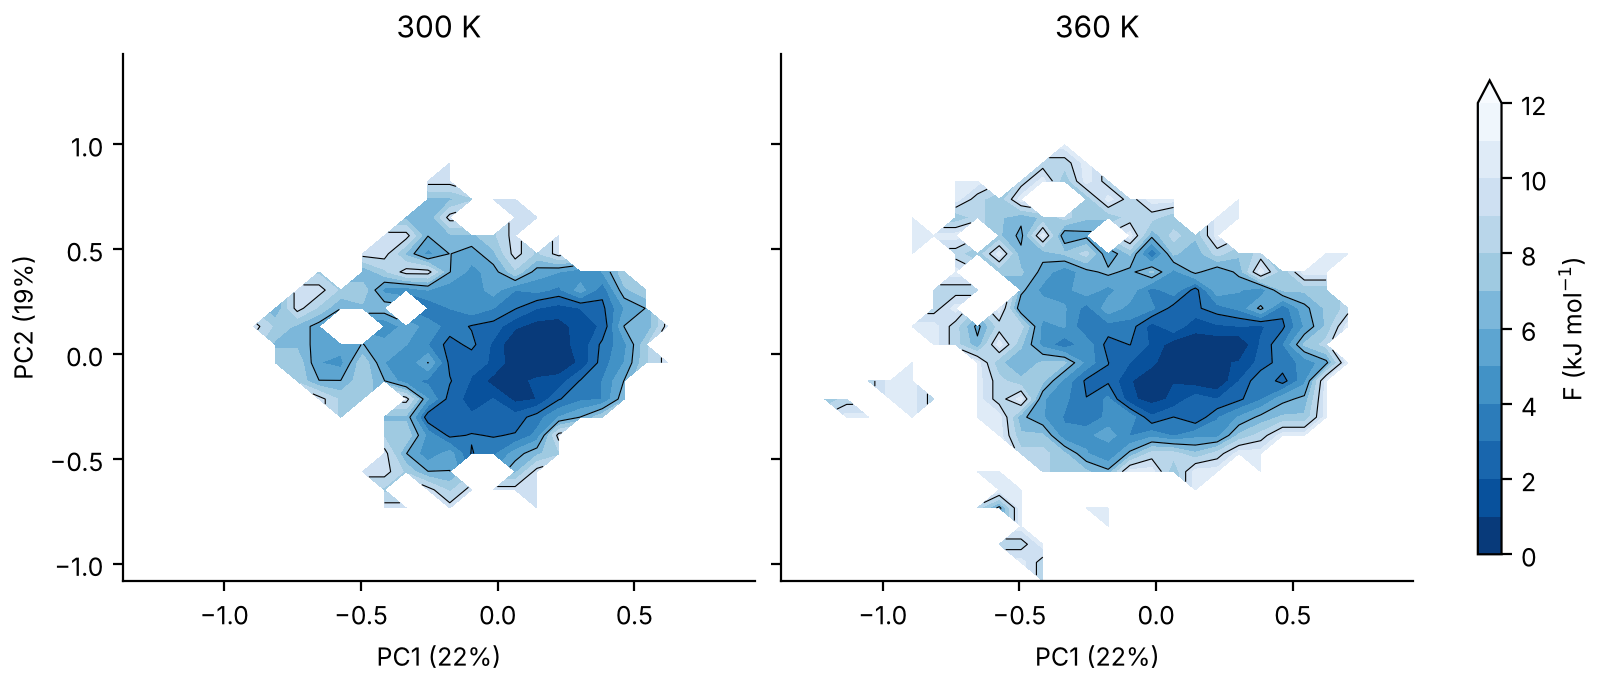

In [ ]:
display(Image('results_advanced/fes_pca.png', width=800))

### 10.3 Validation against the experimental NMR ensemble

The 38 NMR models of 1L2Y differ from model 1 by 0.032–0.135 nm Cα RMSD (median 0.088 nm). The MD frames fall in the same range: the median RMSD to model 1 is 0.078 nm at 300 K and 0.084 nm at 360 K, and 99.5% (300 K) and 93.4% (360 K) of frames lie within the largest NMR deviation.

The per-residue flexibility profiles agree well: Pearson r = 0.79 (300 K) and 0.88 (360 K) between MD RMSF and the RMSF of the NMR ensemble. Both identify the termini and the Gly10–Arg16 loop as the most mobile regions and the helix around Trp6 as the most rigid. The MD values are systematically higher. This is expected, because the spread of an NMR ensemble reflects how tightly the structure is defined by the restraints, not the full amplitude of thermal motion. The simulation therefore reproduces the experimental structure and its pattern of flexibility, which supports the force field and protocol.

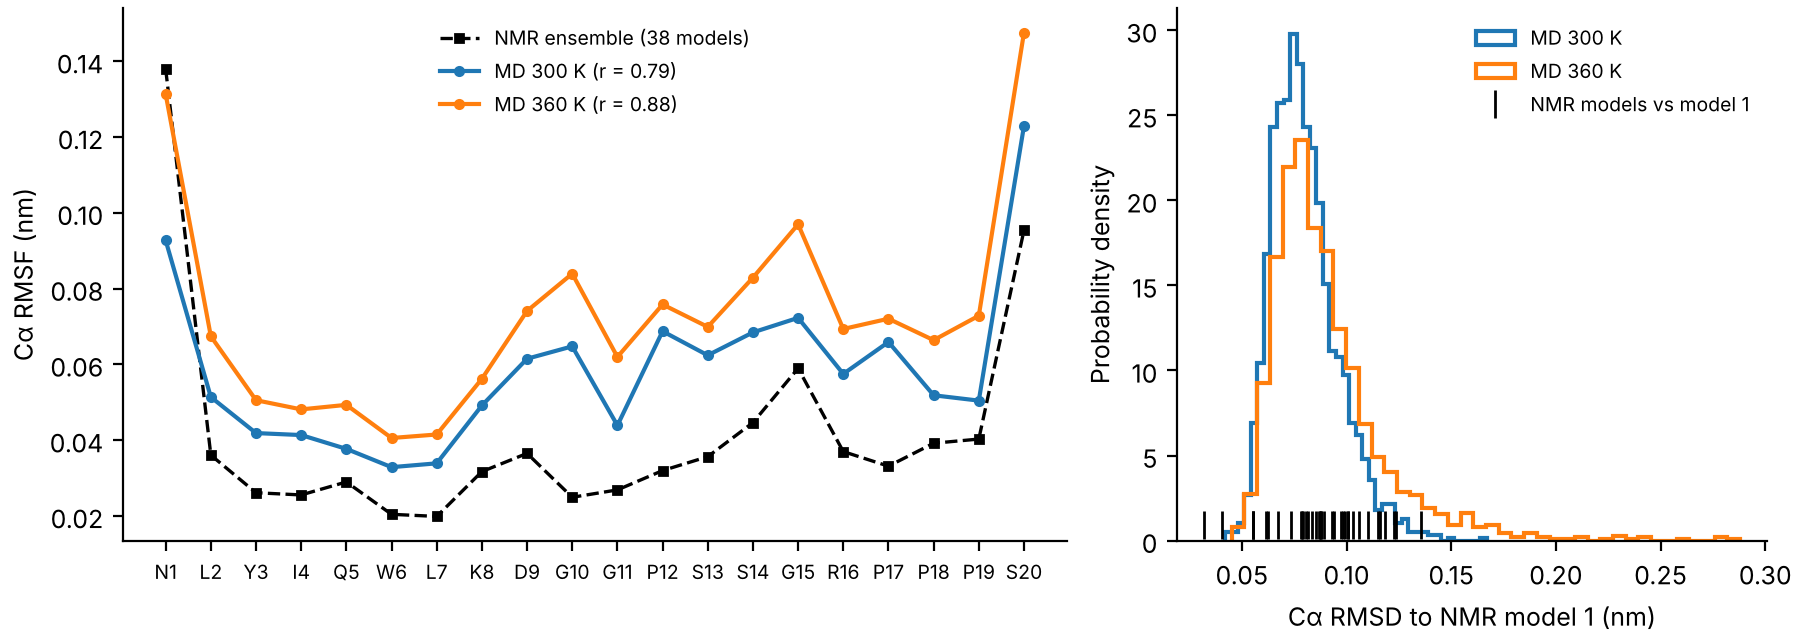

In [ ]:
display(Image('results_advanced/nmr_validation.png', width=800))

### 10.4 What breaks during the excursions? The Asp9–Arg16 salt bridge

At 360 K, 6.2% of frames have Q < 0.92. The main excursions occur at about 7.5–7.7 ns (min Q = 0.85), 10.6–10.7 ns (min Q = 0.87) and from 19.8 ns to the end of the run (min Q = 0.83), so the last one is still in progress when the trajectory ends. The contacts lost most in these frames, with frequency in native-like → excursion frames, are: D9–R16 (0.89 → 0.16), D9–S14 (0.92 → 0.35), Q5–R16 (0.47 → 0.01), D9–S13 (0.46 → 0.18), G10–S14 (0.80 → 0.53). Every one of them involves **Asp9, Arg16** or the loop between them.

The salt-bridge distance explains these dips:
- Q is strongly anti-correlated with the Asp9–Arg16 distance (r = -0.75 at 300 K and -0.77 at 360 K).
- At 360 K the salt bridge is broken in 95% of excursion frames, compared with 17% of native-like frames.

**Control for circularity.** About a quarter of the native contacts in Q involve Asp9 or Arg16, so opening the salt bridge lowers Q *by definition*. Recomputing Q without those contacts removes the dips almost entirely (middle panel). The reduced Q stays above 0.92 in all frames at 300 K and in 99.8% of frames at 360 K (the exceptions are four isolated frames), averages 0.987 (300 K) and 0.986 (360 K), and no longer correlates with the salt-bridge distance (r = 0.26 and -0.19).

**Interpretation.** The low-Q excursions are local events: the Asp9 and Arg16 side chains separate and the Gly10–Arg16 loop rearranges, while the helix and the Trp6/polyproline core stay intact. The large drop at the end of the 360 K run (Q ≈ 0.86, salt-bridge distance ≈ 0.9 nm) is one of these events, not the onset of unfolding. Overall, the salt bridge is formed in similar fractions of time at both temperatures (0.76 and 0.78). It opens and closes on nanosecond time scales: between about 11.5 and 19 ns it is formed in 99% (300 K) and 97% (360 K) of frames. These slow switches are why the 360 K error bars in 10.1 have not converged. The Asp9–Arg16 salt bridge has been identified experimentally as a stabilizing interaction in Trp-cage (Barua et al., 2008). Here it is the first interaction to give way, at both temperatures.

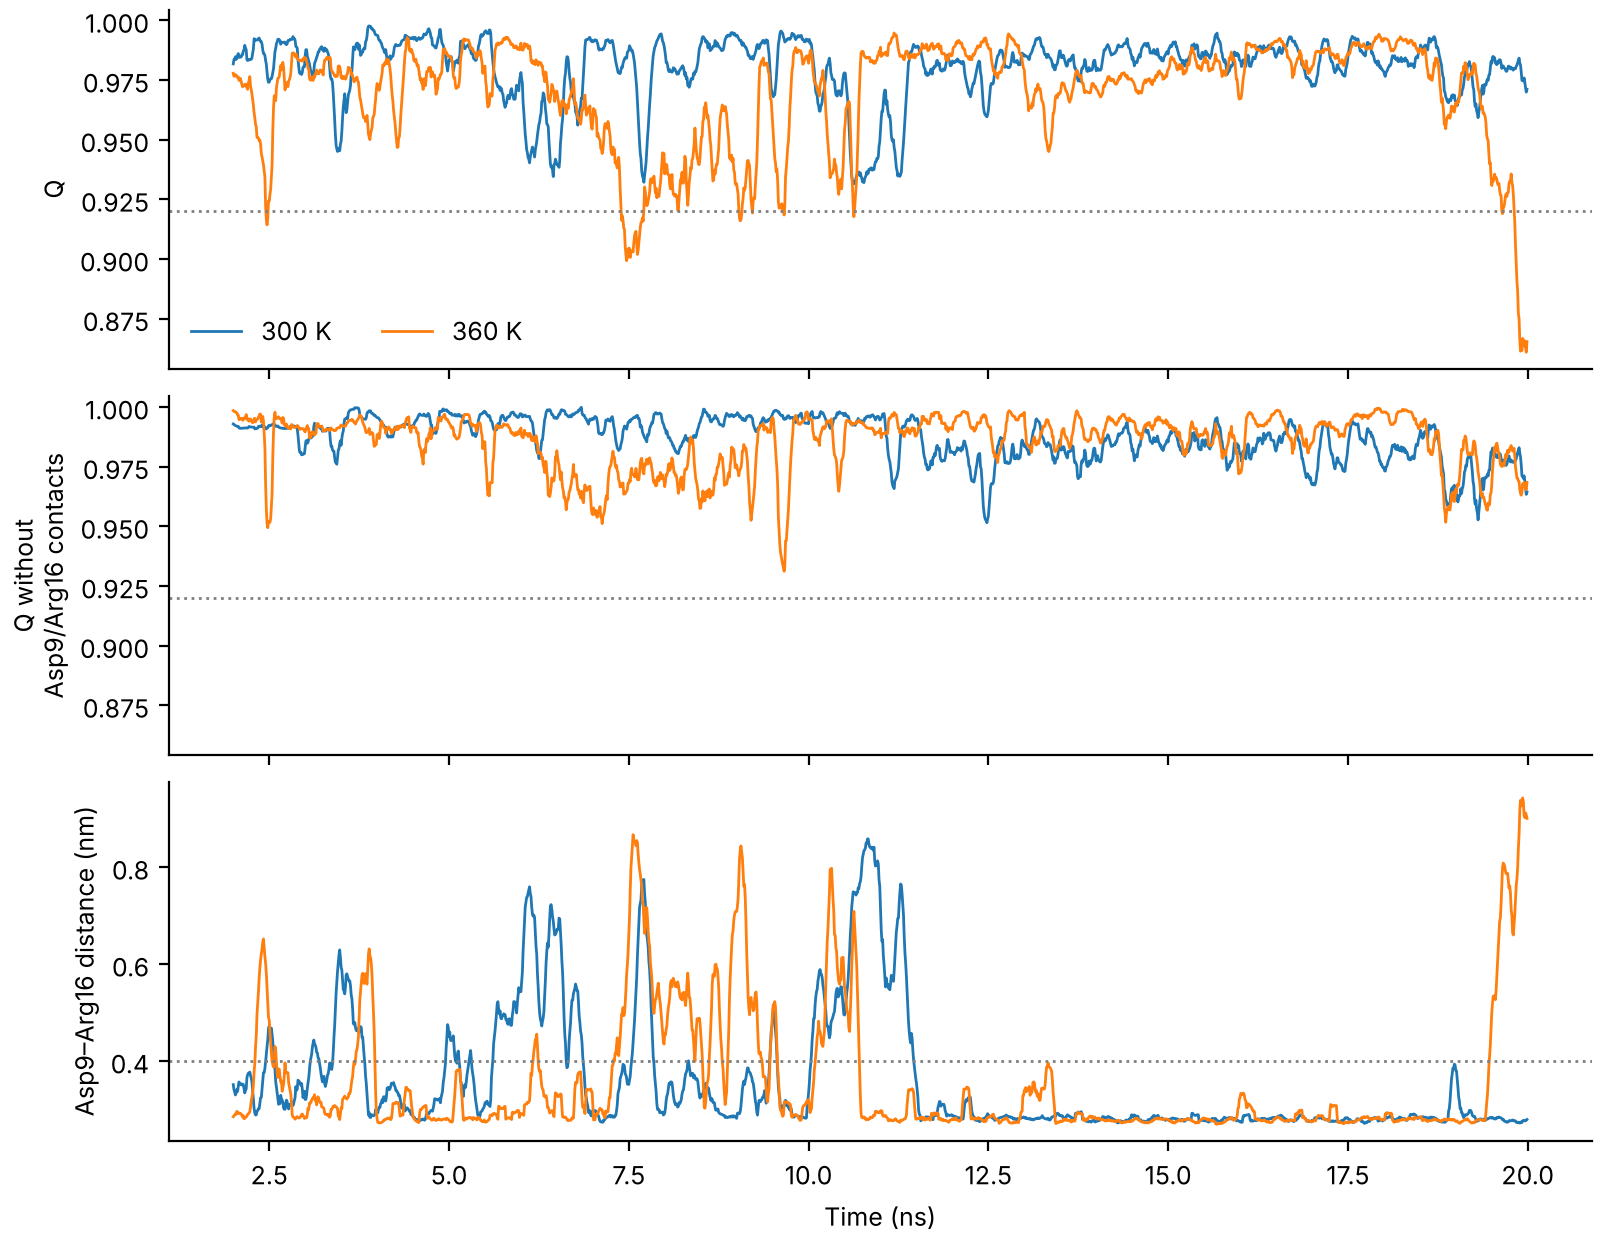

In [ ]:
display(Image('results_advanced/salt_bridge.png', width=800))

### 10.5 Hydrophobic core and contact maps

The Trp6 side chain stays buried at both temperatures. Its solvent-accessible surface area is 0.20 ± 0.01 nm² at 300 K and 0.22 ± 0.01 nm² at 360 K (p = 0.36), and the distributions almost overlap, so the cage does not open.

The difference contact map shows where the structure loosens. The contacts that weaken most at 360 K (frequency at 300 K → 360 K) are Y3–P18 (0.75 → 0.60), R16–P19 (0.23 → 0.12), D9–S14 (0.96 → 0.89), N1–I4 (1.00 → 0.94). These are the packing of the N-terminal residues against the polyproline segment (Tyr3–Pro18) and the contacts around the Asp9–Ser14–Arg16 loop. Some loop contacts *gain* frequency, which indicates that the loop rearranges rather than simply dissolving.

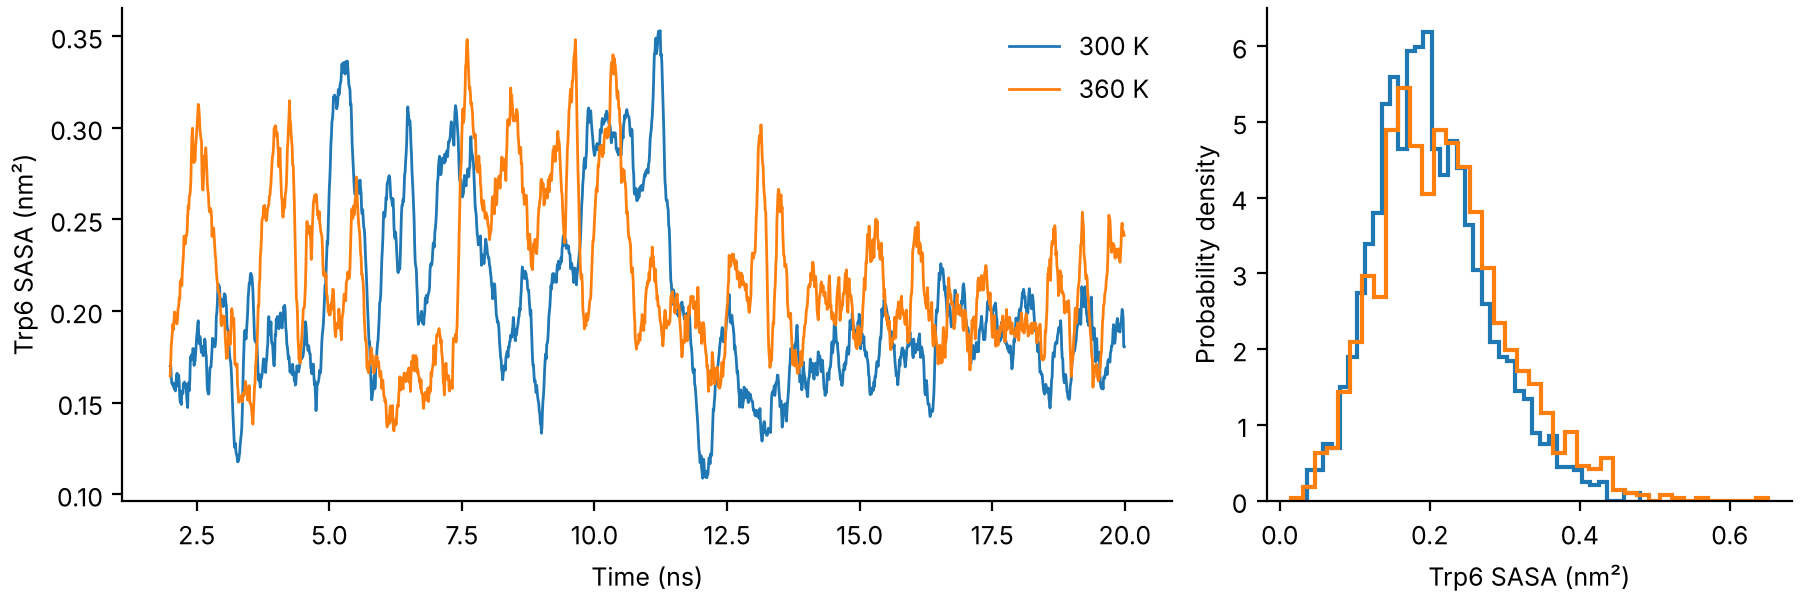

In [ ]:
display(Image('results_advanced/trp6_sasa.png', width=800))

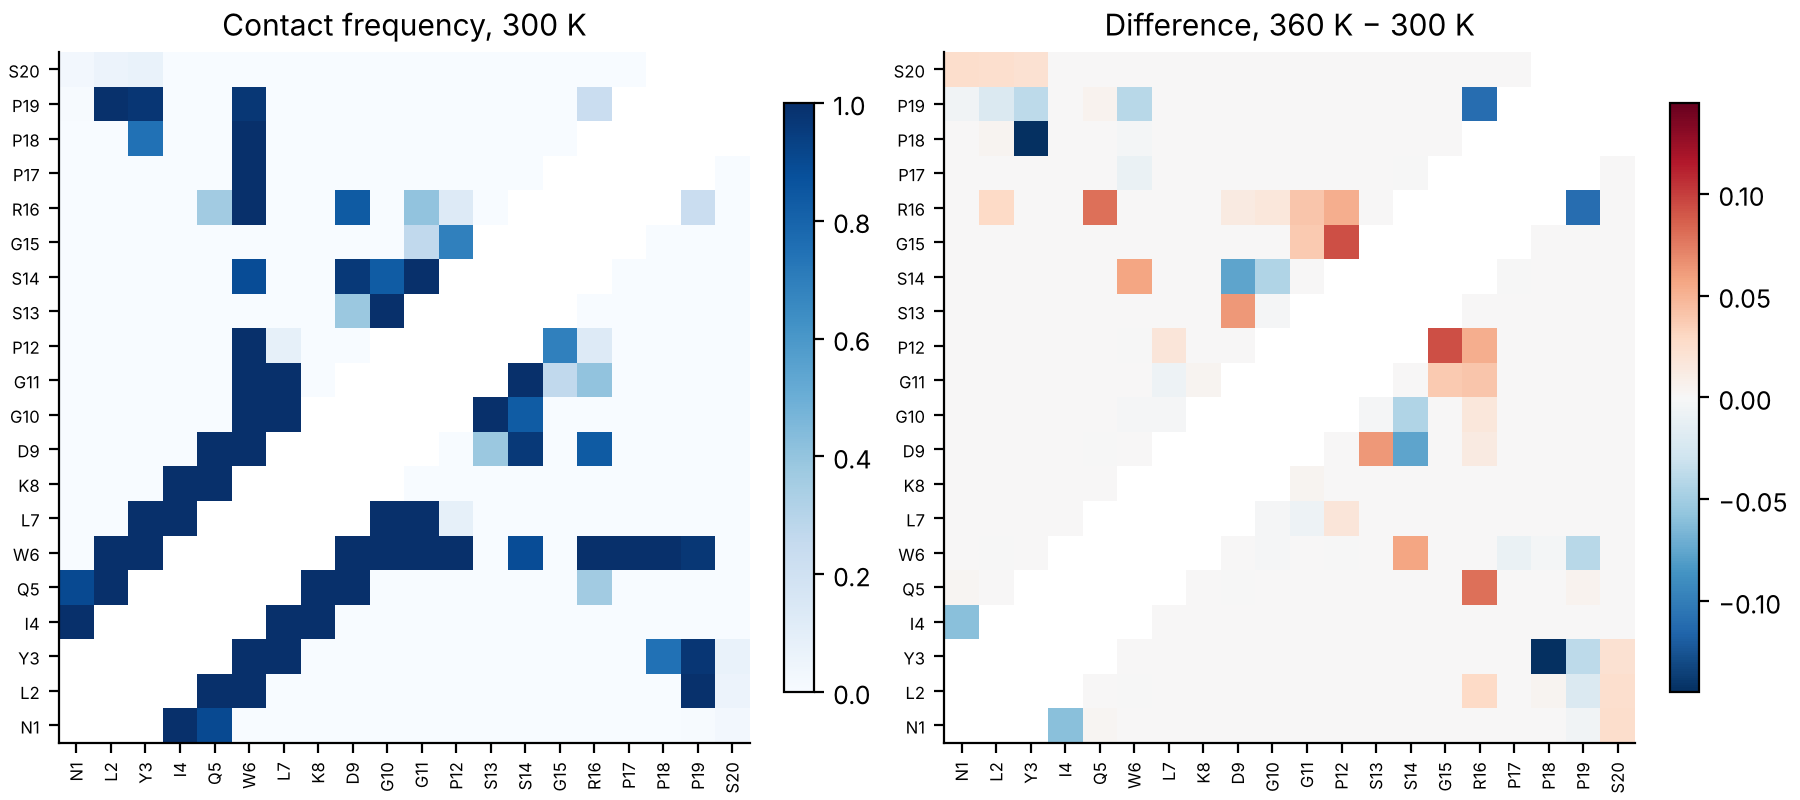

In [ ]:
display(Image('results_advanced/contact_maps.png', width=800))

### 10.6 Interpretable classifier: can the ensembles be told apart?

A logistic-regression model trained on the 190 Cα–Cα distances distinguishes 300 K from 360 K frames with a cross-validated balanced accuracy of **0.62** (folds: 0.56, 0.70, 0.54, 0.72, 0.57; chance = 0.50). Because the cross-validation uses contiguous time blocks, this measures generalization to unseen parts of the trajectory, not memorization of neighbouring frames. The modest accuracy is itself a result: the two ensembles overlap heavily, consistent with the single shared basin in 10.2.

The distances with the largest weights are N1–G15, I4–G15, Y3–P19, N1–R16, D9–R16, L2–P19. They point to the same regions as the contact analysis: the position of the N-terminus relative to the polyproline segment (Tyr3–Pro19, Leu2–Pro19) and the Asp9–Arg16 separation. Some neighbouring features carry opposite signs (e.g. Asn1–Gly15 positive, Ile4–Gly15 negative). This is typical of correlated inputs in a linear model: together they encode a small shift of the N-terminus relative to the loop, so individual coefficients should not be interpreted in isolation.

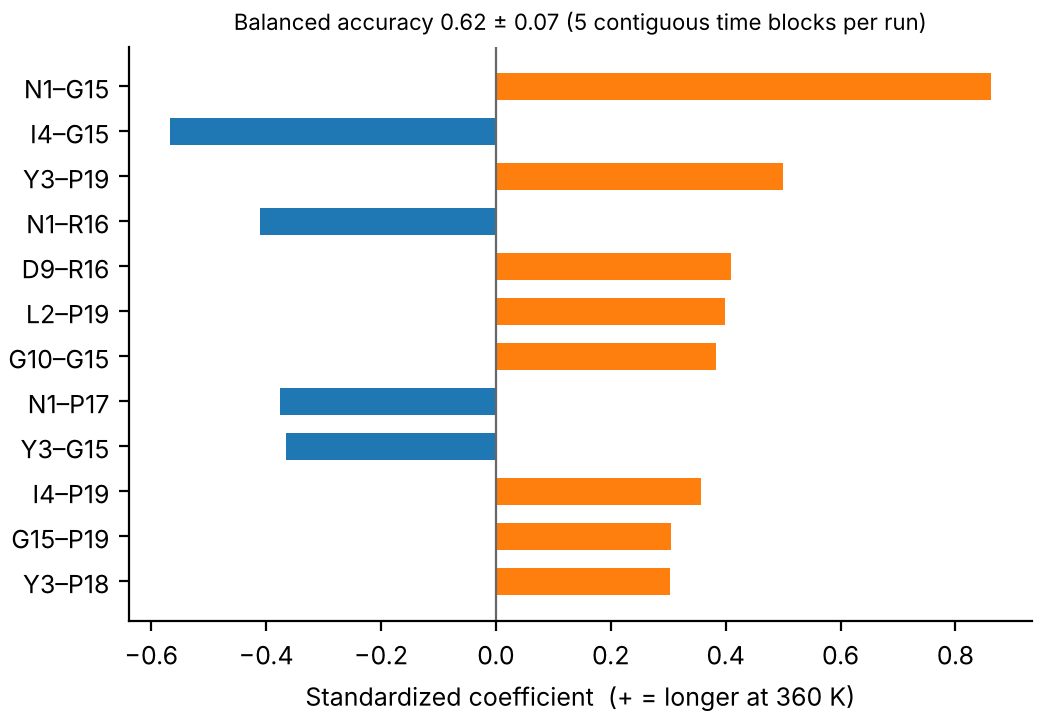

In [ ]:
display(Image('results_advanced/classifier_features.png', width=600))

## 11. Structural visualization

An interactive view of each trajectory (every 20th frame) with py3Dmol, followed by publication-quality PyMOL renderings of the native structure and the final frames.

In [11]:
!pip install -q py3Dmol
import mdtraj as md, py3Dmol

def show(run, stride=20):
    t = md.load(f'{run}/protein.xtc', top=f'{run}/protein_start.pdb')[::stride]
    t.superpose(t, 0, atom_indices=t.topology.select('name CA'))
    t.save_pdb('/tmp/movie.pdb')
    v = py3Dmol.view(width=500, height=400)
    v.addModelsAsFrames(open('/tmp/movie.pdb').read())
    v.setStyle({'cartoon': {'color': 'spectrum'}})
    v.addStyle({'resn': 'TRP'}, {'stick': {}})   # show Trp6, the core of the cage
    v.zoomTo(); v.animate({'loop': 'forward', 'interval': 200})
    return v.show()

show('runs/T300')

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
%%capture
# PyMOL (open source); --no-deps keeps Colab's NumPy unchanged
!pip install -q --no-deps pymol-open-source-whl

T300: 2000 frames
T360: 2000 frames
saved images/start.png
saved images/T300_final.png
saved images/T360_final.png
saved images/overlay_final.png
start


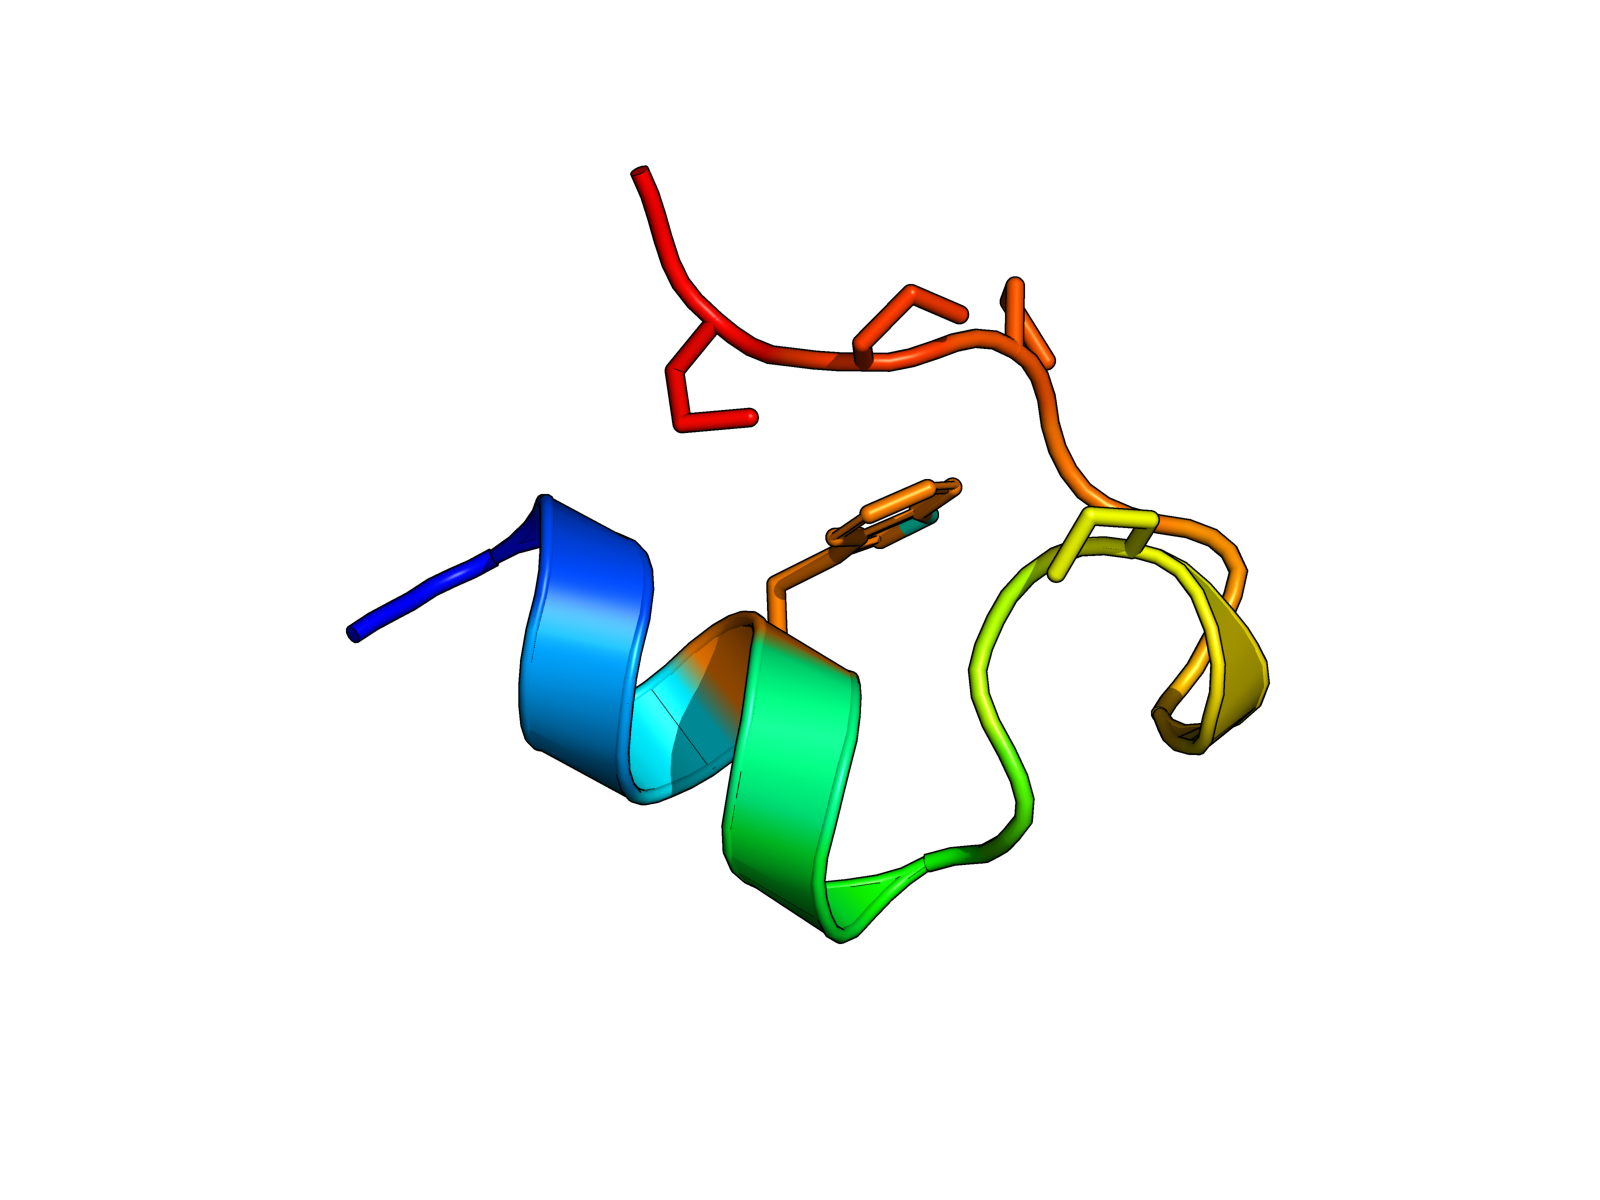

T300_final


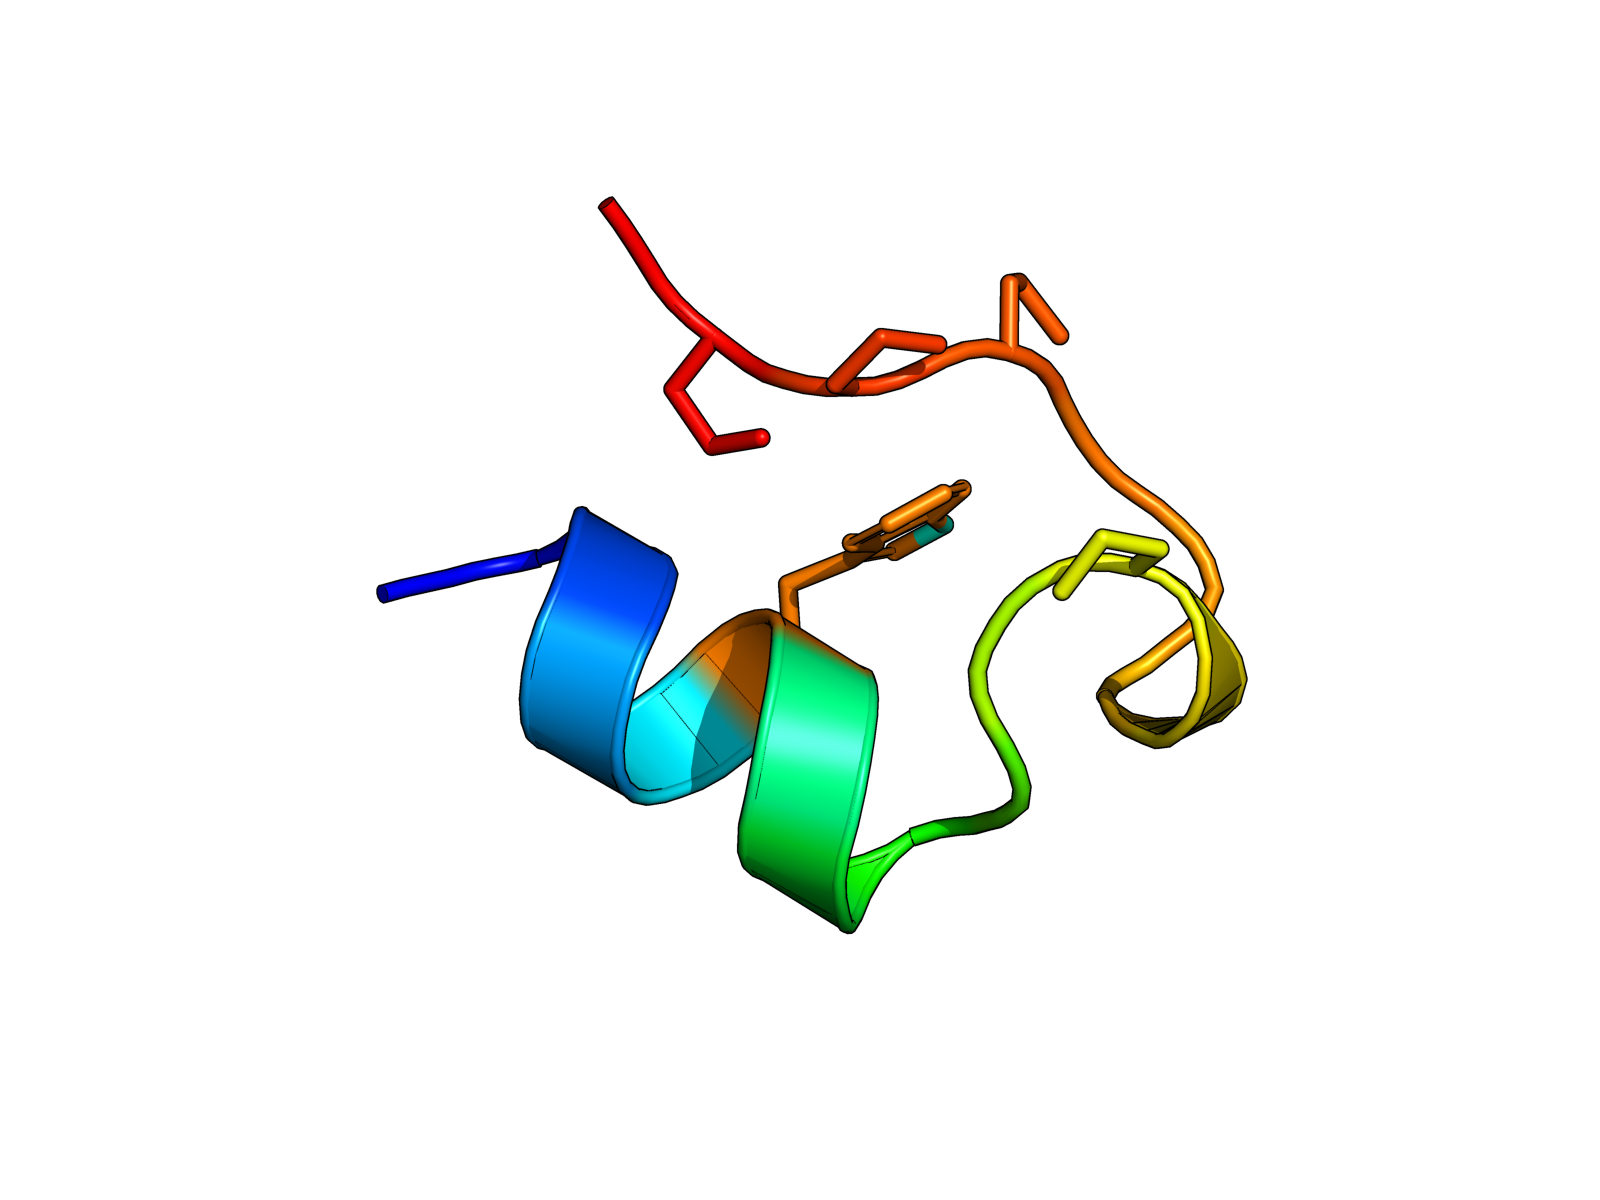

T360_final


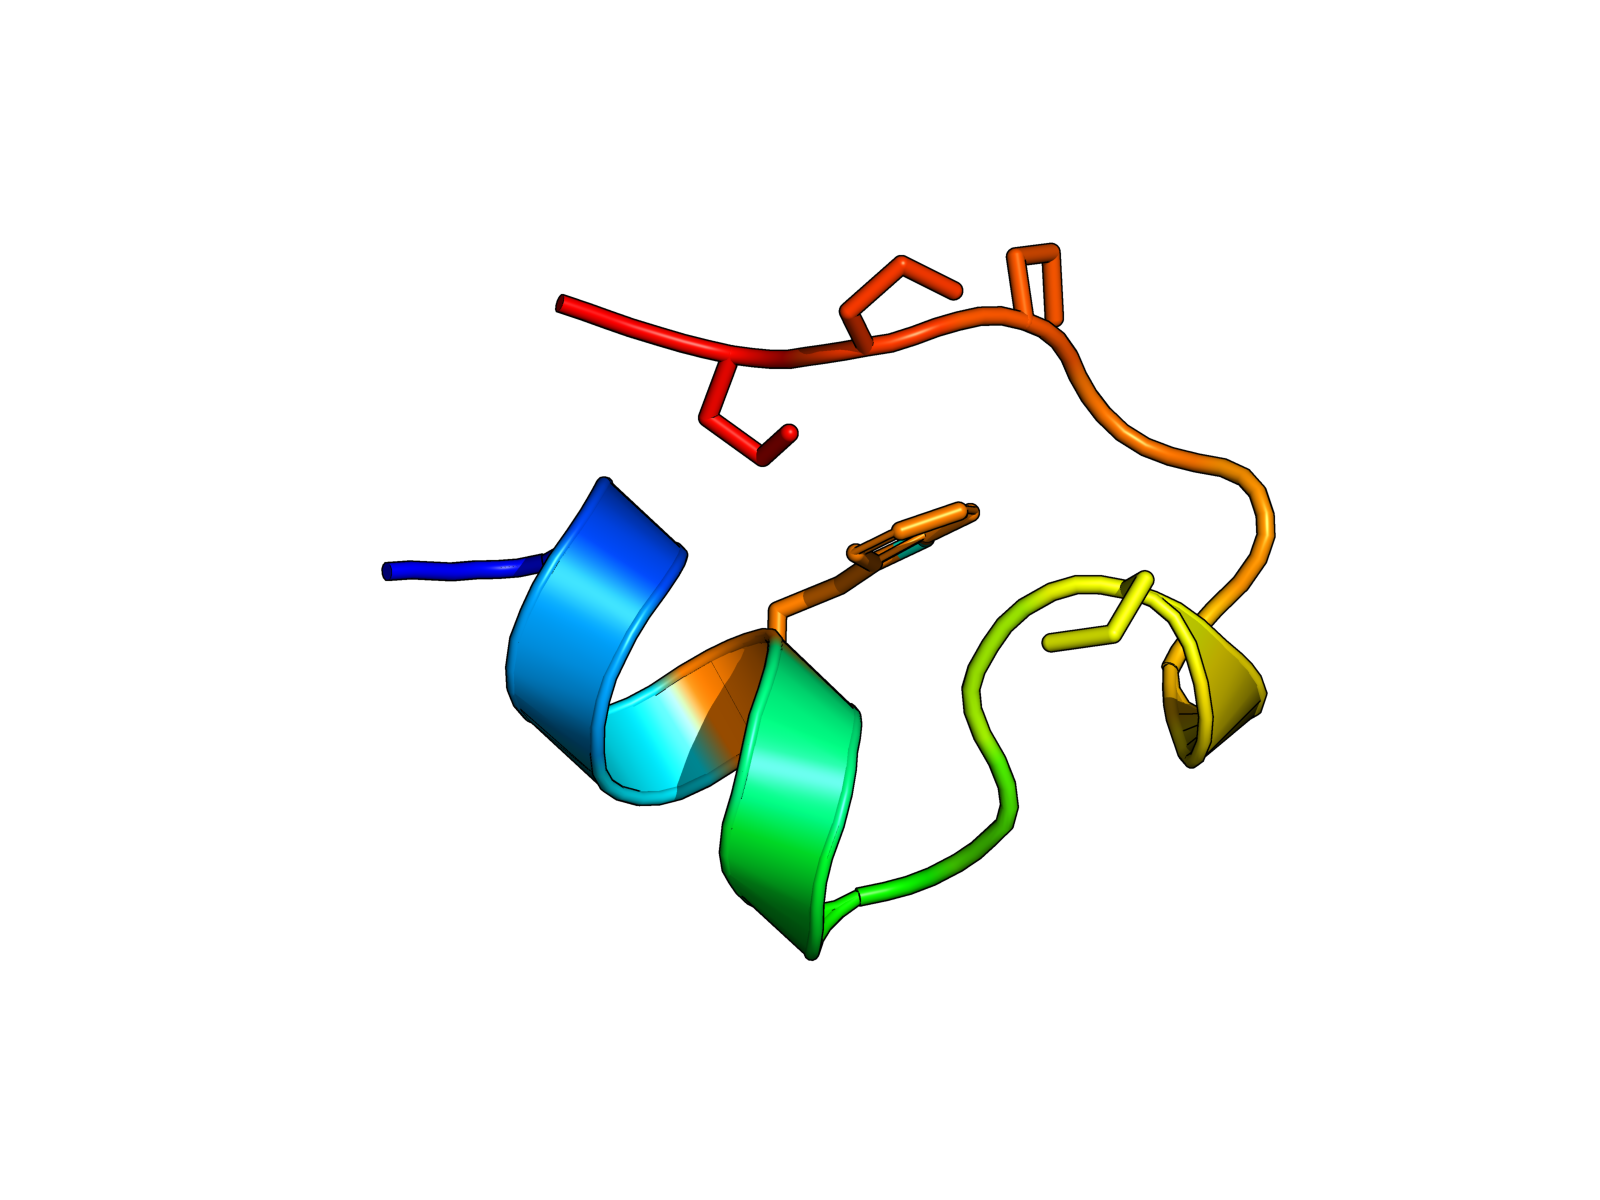

overlay_final


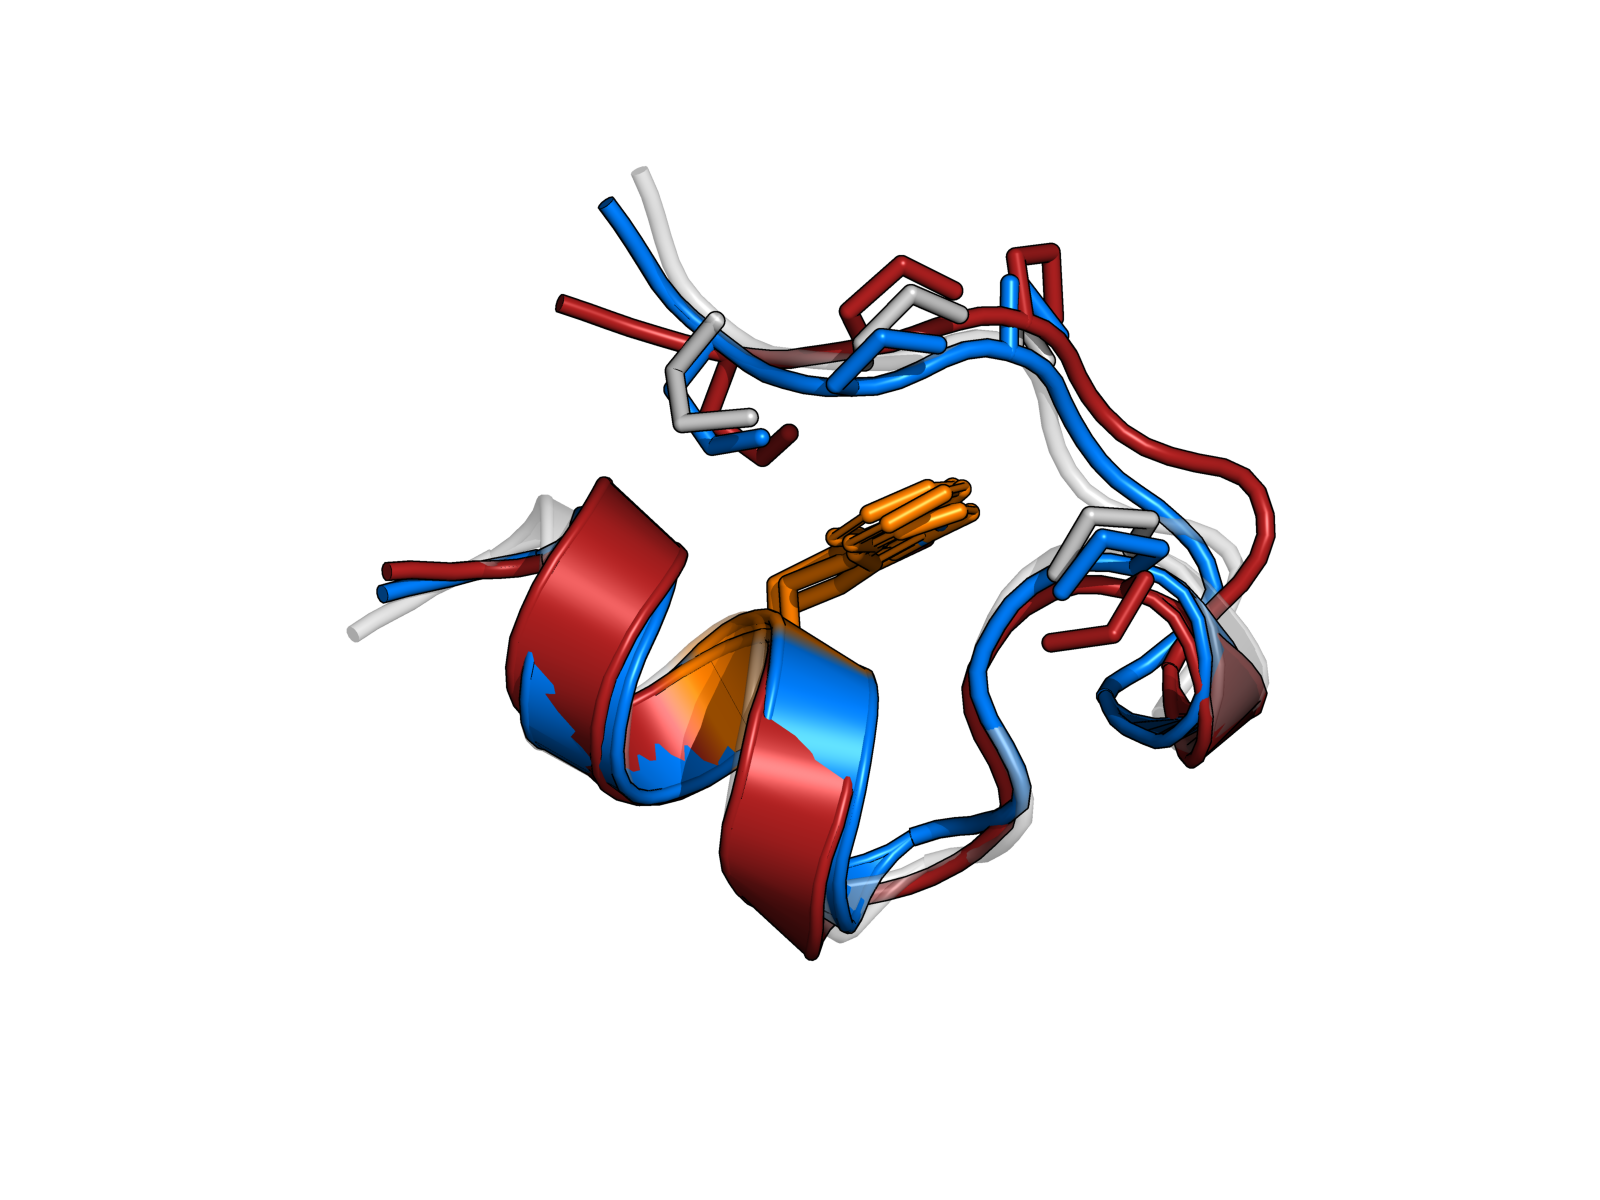

In [12]:
import pymol
pymol.finish_launching(["pymol", "-cq"])
import os
from pymol import cmd
from IPython.display import Image, display

RUNS = {"T300": "runs/T300", "T360": "runs/T360"}
COLORS = {"T300": "marine", "T360": "firebrick"}
OUT = "images"
WIDTH, HEIGHT, DPI = 1600, 1200, 300


def style_scene():
    cmd.bg_color("white")
    cmd.set("ray_opaque_background", 1)
    cmd.set("cartoon_transparency", 0)
    cmd.set("cartoon_fancy_helices", 1)
    cmd.set("cartoon_side_chain_helper", 1)
    cmd.set("stick_radius", 0.2)
    cmd.set("ray_trace_mode", 1)
    cmd.set("antialias", 2)
    cmd.set("orthoscopic", 1)
    cmd.set("depth_cue", 0)


def show_protein(obj, color=None):
    cmd.hide("everything", obj)
    cmd.show("cartoon", obj)
    if color:
        cmd.color(color, obj)
    else:
        cmd.spectrum("resi", "rainbow", obj)

    cmd.show("sticks", f"{obj} and (resn TRP or resi 12+17+18+19) and not name N+C+O")
    cmd.color("orange", f"{obj} and resn TRP and elem C")
    cmd.hide("everything", f"{obj} and hydro")


def render(name):
    path = os.path.join(OUT, name)
    cmd.ray(WIDTH, HEIGHT)
    cmd.png(path, dpi=DPI)
    print(f"saved {path}")


def main():
    os.makedirs(OUT, exist_ok=True)
    cmd.reinitialize()
    style_scene()

    cmd.load(os.path.join(RUNS["T300"], "protein_start.pdb"), "native")

    finals = []
    for name, folder in RUNS.items():
        cmd.load(os.path.join(folder, "protein_start.pdb"), name)
        cmd.load_traj(os.path.join(folder, "protein.xtc"), name, state=1)
        n = cmd.count_states(name)
        print(f"{name}: {n} frames")

        final = f"{name}_final"
        cmd.create(final, name, n, 1)
        cmd.align(f"{final} and name CA", "native and name CA", cycles=0)
        finals.append(final)
        cmd.disable(name)


    cmd.disable("all")
    cmd.enable("native")
    show_protein("native")
    cmd.orient("native")
    view = cmd.get_view()
    render("start.png")

    for final in finals:
        cmd.disable("all")
        cmd.enable(final)
        show_protein(final)
        cmd.set_view(view)
        render(f"{final}.png")

    cmd.disable("all")
    cmd.enable("native")
    show_protein("native", "grey80")
    cmd.set("cartoon_transparency", 0.5, "native")
    for final in finals:
        cmd.enable(final)
        show_protein(final, COLORS[final.split("_")[0]])
    cmd.set_view(view)
    render("overlay_final.png")


main()
for f in ["start", "T300_final", "T360_final", "overlay_final"]:
    print(f)
    display(Image(f"{OUT}/{f}.png", width=600))

### Structural comparison of final frames

**Figure: `overlay_final.png`.** Final frames of both trajectories superposed on the Cα atoms of the native structure (colour key below).

| Colour | Representation | Structure |
|---|---|---|
| Transparent grey | Cartoon | Native starting structure (minimized 1L2Y, model 1) |
| Blue | Cartoon | Final frame of the 300 K trajectory (t = 20 ns) |
| Red | Cartoon | Final frame of the 360 K trajectory (t = 20 ns) |
| Orange | Sticks | Trp6 side chain (core of the hydrophobic cage) |
| Same colour as its chain | Thin sticks | Pro12, Pro17, Pro18, Pro19 side chains (packing against Trp6) |

The 300 K final frame is close to the native structure throughout (Cα RMSD 0.08 nm; no residue deviates by more than 0.13 nm). The 360 K final frame (Cα RMSD 0.14 nm) was captured during the salt-bridge-opening excursion described in 10.4 (Asp9–Arg16 distance ≈ 0.9 nm). Its largest deviations are at the C-terminal Ser20 (0.36 nm), Asn1 (0.21 nm) and the Asp9–Arg16 loop (0.15–0.18 nm). Trp6, Leu7, Pro17 and Pro18 stay within 0.08 nm of their native positions, so the helix and the Trp6–proline cage are intact even in this most perturbed snapshot.

A single frame includes instantaneous fluctuations; the time-averaged analyses in sections 9 and 10 are the quantitative evidence.

## 12. Discussion

**Native-state stability and validation.** At 300 K, Trp-cage stays in its native fold for the full 20 ns (Cα RMSD 0.083 ± 0.002 nm, Q = 0.980 ± 0.002). The simulated ensemble overlaps with the experimental NMR ensemble: almost all frames lie within its RMSD range, and the per-residue flexibility profile correlates with the NMR spread (r = 0.79). This validates the setup (AMBER ff14SB, TIP3P-FB, 4 fs time step with hydrogen-mass repartitioning) for this system.

**Effect of temperature.** At 360 K the protein stays in the same native basin. Only the Cα RMSD increases significantly (+0.012 nm, p < 0.001). Compactness, helicity and burial of Trp6 are unchanged within error. Heating therefore *broadens* the native basin rather than moving the protein out of it. This is confirmed independently by the free-energy landscapes (one basin with a shallow shoulder) and by the classifier, which can barely separate the two ensembles (balanced accuracy 0.62).

**Mechanism of the excursions.** The temperature-sensitive part of the structure is the Asp9–Arg16 salt bridge and the loop it closes. Almost every low-Q frame at 360 K (95%), including those of the large excursion at the end of the run, coincides with an open salt bridge. Once contacts involving these two residues are removed from Q, the excursions almost disappear. In other words, the side chains of this electrostatic interaction rearrange, while the hydrophobic Trp6 core and the helix stay intact. Heating also weakens the packing of the N-terminus against the polyproline segment (Tyr3–Pro18 contact frequency 0.75 → 0.60), the second-most sensitive region.

**Why no unfolding?** This outcome is expected for three reasons:
1. Trp-cage folds and unfolds on microsecond time scales, at least two orders of magnitude longer than these runs (Qiu et al., 2002; Lindorff-Larsen et al., 2011).
2. Unfolding is a rare barrier-crossing event, so it is unlikely to be seen in a single short trajectory even above the melting temperature.
3. Fixed-charge force fields tend to over-stabilize Trp-cage, which shifts its simulated melting temperature above the experimental ~315 K.

The salt-bridge excursions are therefore best read as the *earliest* response to heating that can be observed on the nanosecond time scale.

**Limitations**
- There is one 20 ns trajectory per temperature. The block-averaging check shows that the 360 K uncertainties are not converged (they are lower bounds), and the free-energy landscapes are only qualitative in their high-F regions.
- 20 ns is far shorter than the folding time scale, so no conclusion about the unfolded state or the melting temperature is possible.
- Only the Cα RMSD difference is statistically significant. Other trends (Q, Trp6 SASA, individual contacts) are suggestive at best.
- The classifier's coefficients come from correlated features and should be read as regional patterns, not as effects of individual distances.

**Next steps**
- **Replicas:** 3 or more independent replicas per temperature (supported by `analyze_advanced.py`), for error bars between replicas and leave-one-replica-out classification.
- **Longer sampling or more temperatures:** e.g. 100 ns runs, or 400–450 K in NVT to avoid boiling the water box, to observe unfolding of the core.
- **Enhanced sampling:** replica-exchange MD to estimate a melting curve from ⟨Q⟩(T).
- **Salt-bridge test:** an in-silico D9N or R16A mutant to test directly whether removing the salt bridge destabilizes the fold.

## 13. Conclusions

1. The simulation protocol reproduces the experimental structure of Trp-cage and its pattern of flexibility, as checked against the 38-model NMR ensemble.
2. Heating from 300 K to 360 K broadens the native basin but does not unfold the protein on a 20 ns time scale.
3. The first interaction to respond is the Asp9–Arg16 salt bridge. Its opening accounts for almost all transient losses of native contacts, while the hydrophobic Trp6 cage stays intact.
4. Block-averaging diagnostics show that replicas are needed for converged statistics at elevated temperature. The analysis pipeline is already set up for them.

## References

- Barua, B. et al. (2008). The Trp-cage: optimizing the stability of a globular miniprotein. *Protein Engineering, Design and Selection* 21, 171–185.
- Best, R. B., Hummer, G. & Eaton, W. A. (2013). Native contacts determine protein folding mechanisms in atomistic simulations. *PNAS* 110, 17874–17879.
- Eastman, P. et al. (2017). OpenMM 7: rapid development of high performance algorithms for molecular dynamics. *PLoS Computational Biology* 13, e1005659.
- Hopkins, C. W. et al. (2015). Long-time-step molecular dynamics through hydrogen mass repartitioning. *Journal of Chemical Theory and Computation* 11, 1864–1874.
- Kabsch, W. & Sander, C. (1983). Dictionary of protein secondary structure. *Biopolymers* 22, 2577–2637.
- Lindorff-Larsen, K. et al. (2011). How fast-folding proteins fold. *Science* 334, 517–520.
- Maier, J. A. et al. (2015). ff14SB: improving the accuracy of protein side chain and backbone parameters from ff99SB. *Journal of Chemical Theory and Computation* 11, 3696–3713.
- McGibbon, R. T. et al. (2015). MDTraj: a modern open library for the analysis of molecular dynamics trajectories. *Biophysical Journal* 109, 1528–1532.
- Neidigh, J. W., Fesinmeyer, R. M. & Andersen, N. H. (2002). Designing a 20-residue protein. *Nature Structural Biology* 9, 425–430.
- Qiu, L. et al. (2002). Smaller and faster: the 20-residue Trp-cage protein folds in 4 µs. *Journal of the American Chemical Society* 124, 12952–12953.
- Wang, L.-P., Martinez, T. J. & Pande, V. S. (2014). Building force fields: an automatic, systematic, and reproducible approach. *Journal of Physical Chemistry Letters* 5, 1885–1891.

*Code was developed with AI-assisted programming (Claude). All analyses were run, checked and interpreted by the author.*